In [201]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb

plt.rcParams["font.sans-serif"] = "Microsoft YaHei"

In [202]:
index_names = ['unit_number', 'time_cycles']
setting_names = ['setting_1', 'setting_2', 'setting_3']
sensor_names = ['s_{}'.format(i+1) for i in range(0, 21)]
col_names = index_names + setting_names + sensor_names
print(col_names)

['unit_number', 'time_cycles', 'setting_1', 'setting_2', 'setting_3', 's_1', 's_2', 's_3', 's_4', 's_5', 's_6', 's_7', 's_8', 's_9', 's_10', 's_11', 's_12', 's_13', 's_14', 's_15', 's_16', 's_17', 's_18', 's_19', 's_20', 's_21']


In [203]:
df_train = pd.read_csv('../raw/CMaps/train_FD001.txt', sep=r'\s+', header=None, index_col=False, names=col_names)
df_valid = pd.read_csv('../raw/CMaps/test_FD001.txt', sep=r'\s+', header=None, index_col=False, names=col_names)
y_valid = pd.read_csv('../raw/CMaps/RUL_FD001.txt', sep=r'\s+', header=None, index_col=False, names=['RUL'])
df_valid.shape

(13096, 26)

In [204]:
train = df_train.copy()
valid = df_valid.copy()

## 描述性统计

In [205]:
train

,unit_number,time_cycles,setting_1,setting_2,setting_3,s_1,s_2,s_3,s_4,s_5,...,s_12,s_13,s_14,s_15,s_16,s_17,s_18,s_19,s_20,s_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20626,100,196,-0.0004,-0.0003,100.0,518.67,643.49,1597.98,1428.63,14.62,...,519.49,2388.26,8137.60,8.4956,0.03,397,2388,100.0,38.49,22.9735
20627,100,197,-0.0016,-0.0005,100.0,518.67,643.54,1604.50,1433.58,14.62,...,519.68,2388.22,8136.50,8.5139,0.03,395,2388,100.0,38.30,23.1594
20628,100,198,0.0004,0.0000,100.0,518.67,643.42,1602.46,1428.18,14.62,...,520.01,2388.24,8141.05,8.5646,0.03,398,2388,100.0,38.44,22.9333
20629,100,199,-0.0011,0.0003,100.0,518.67,643.23,1605.26,1426.53,14.62,...,519.67,2388.23,8139.29,8.5389,0.03,395,2388,100.0,38.29,23.0640


In [206]:
print('Shape of train:', train.shape)
print('Shape of valid:', valid.shape)
print('Percentage of valid', len(valid)/(len(valid) + len(train)))

Shape of train: (20631, 26)
Shape of valid: (13096, 26)
Percentage of valid 0.3882942449669404


In [207]:
print('Total None Values in the train dataset:', train.isna().sum())

Total None Values in the train dataset: unit_number    0
time_cycles    0
setting_1      0
setting_2      0
setting_3      0
s_1            0
s_2            0
s_3            0
s_4            0
s_5            0
s_6            0
s_7            0
s_8            0
s_9            0
s_10           0
s_11           0
s_12           0
s_13           0
s_14           0
s_15           0
s_16           0
s_17           0
s_18           0
s_19           0
s_20           0
s_21           0
dtype: int64


In [208]:
train.loc[:, ['unit_number', 'time_cycles']].describe()

,unit_number,time_cycles
count,20631.000000,20631.000000
mean,51.506568,108.807862
std,29.227633,68.880990
min,1.000000,1.000000
25%,26.000000,52.000000
50%,52.000000,104.000000
75%,77.000000,156.000000
max,100.000000,362.000000


In [209]:
train.groupby('unit_number')['time_cycles'].describe()['max'].describe()

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: max, dtype: float64

In [210]:
train.loc[:,'s_1':].describe().T

,count,mean,std,min,25%,50%,75%,max
s_1,20631.0,518.670000,0.000000e+00,518.6700,518.6700,518.6700,518.6700,518.6700
s_2,20631.0,642.680934,5.000533e-01,641.2100,642.3250,642.6400,643.0000,644.5300
s_3,20631.0,1590.523119,6.131150e+00,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100
s_4,20631.0,1408.933782,9.000605e+00,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900
s_5,20631.0,14.620000,5.329200e-15,14.6200,14.6200,14.6200,14.6200,14.6200
s_6,20631.0,21.609803,1.388985e-03,21.6000,21.6100,21.6100,21.6100,21.6100
s_7,20631.0,553.367711,8.850923e-01,549.8500,552.8100,553.4400,554.0100,556.0600
s_8,20631.0,2388.096652,7.098548e-02,2387.9000,2388.0500,2388.0900,2388.1400,2388.5600
s_9,20631.0,9065.242941,2.208288e+01,9021.7300,9053.1000,9060.6600,9069.4200,9244.5900
s_10,20631.0,1.300000,0.000000e+00,1.3000,1.3000,1.3000,1.3000,1.3000


## 可视化

In [211]:
plt.style.use('Solarize_Light2')

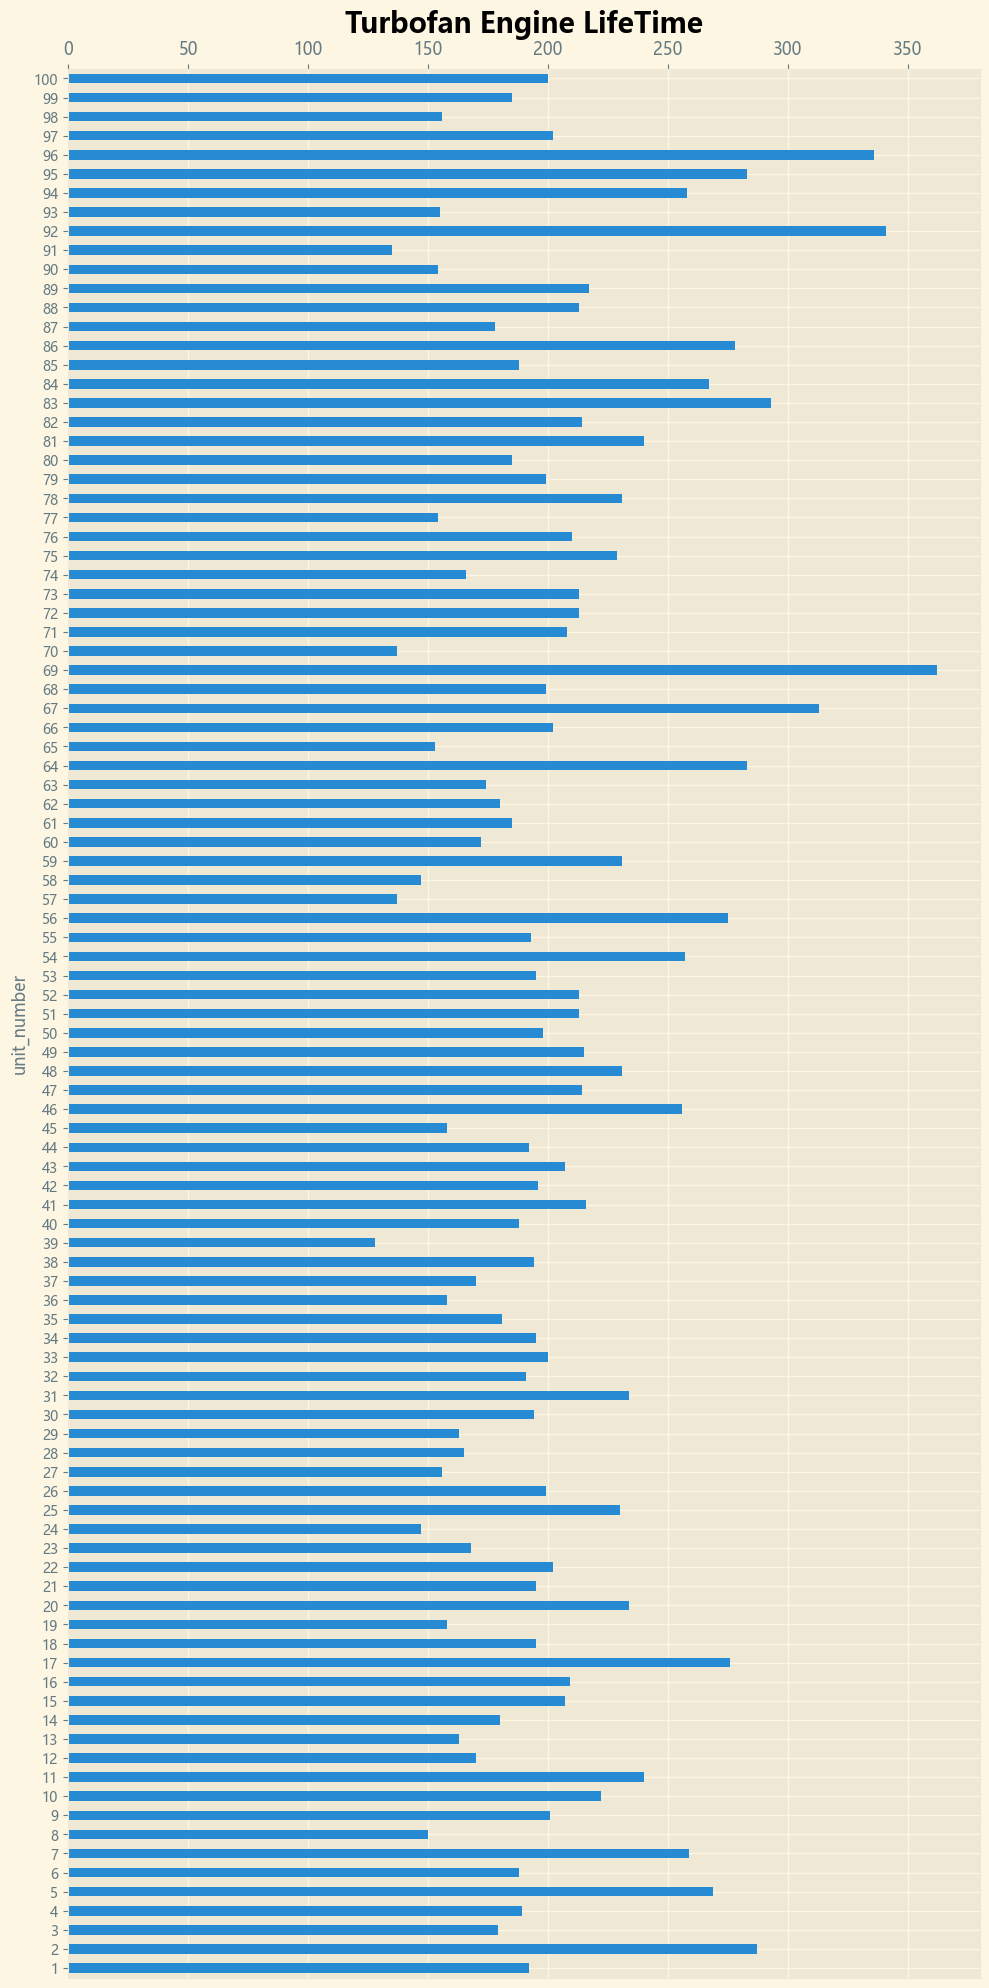

In [212]:
max_time_cycles = train.groupby('unit_number')['time_cycles'].max()
plt.figure(figsize=(10, 20))
ax = max_time_cycles.plot(kind='barh')
ax.xaxis.tick_top()
plt.title('Turbofan Engine LifeTime',
          fontdict={"weight":'bold', 'size':20})
plt.xticks(fontsize=12)
plt.yticks(fontsize=10)
plt.grid(True)
plt.tight_layout()
plt.show()

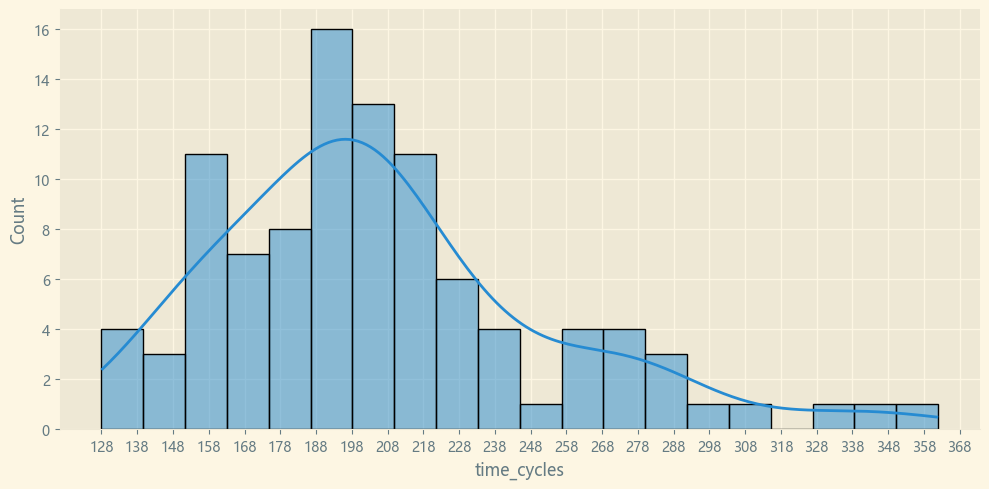

In [213]:
sns.displot(max_time_cycles.reset_index()['time_cycles'], kde=True, aspect=2, bins=20)
plt.xticks(range(max_time_cycles.min(), max_time_cycles.max()+10, 10))
plt.tight_layout()
plt.show()

生成RUL

In [214]:
train['max_time_cycles'] = train.groupby('unit_number')['time_cycles'].transform('max')
train['RUL'] = train['max_time_cycles'] - train['time_cycles']
del train['max_time_cycles']

In [215]:
train[['unit_number', 'RUL']]

,unit_number,RUL
0,1,191
1,1,190
2,1,189
3,1,188
4,1,187
...,...,...
20626,100,4
20627,100,3
20628,100,2
20629,100,1


In [216]:
train.corr()

,unit_number,time_cycles,setting_1,setting_2,setting_3,s_1,s_2,s_3,s_4,s_5,...,s_13,s_14,s_15,s_16,s_17,s_18,s_19,s_20,s_21,RUL
unit_number,1.000000,0.078753,-0.017895,-0.006197,NaN,NaN,0.014133,0.012621,0.026116,NaN,...,0.044230,-0.059473,0.022486,NaN,0.013513,NaN,NaN,-0.020589,-0.016465,0.078753
time_cycles,0.078753,1.000000,-0.004527,0.016132,NaN,NaN,0.549898,0.543947,0.624577,NaN,...,0.477523,0.370324,0.588676,NaN,0.566995,NaN,NaN,-0.583597,-0.585923,-0.736241
setting_1,-0.017895,-0.004527,1.000000,0.011660,NaN,NaN,0.009030,-0.005651,0.009544,NaN,...,0.002318,-0.004469,0.007652,NaN,0.002599,NaN,NaN,-0.005713,-0.014559,-0.003198
setting_2,-0.006197,0.016132,0.011660,1.000000,NaN,NaN,0.007266,0.009068,0.014673,NaN,...,0.018156,-0.006310,0.014156,NaN,0.012280,NaN,NaN,-0.010554,-0.007846,-0.001948
setting_3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
s_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
s_2,0.014133,0.549898,0.009030,0.007266,NaN,NaN,1.000000,0.602610,0.714949,NaN,...,0.661792,0.179752,0.675975,NaN,0.629886,NaN,NaN,-0.661841,-0.668050,-0.606484
s_3,0.012621,0.543947,-0.005651,0.009068,NaN,NaN,0.602610,1.000000,0.678413,NaN,...,0.600963,0.237137,0.639921,NaN,0.600017,NaN,NaN,-0.625941,-0.633901,-0.584520
s_4,0.026116,0.624577,0.009544,0.014673,NaN,NaN,0.714949,0.678413,1.000000,NaN,...,0.745158,0.190748,0.758459,NaN,0.703499,NaN,NaN,-0.748067,-0.745193,-0.678948
s_5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [217]:
# 1. 重复行检查
print('重复行数量:', train.duplicated().sum())
print('valid重复行数量:', valid.duplicated().sum())

重复行数量: 0
valid重复行数量: 0


In [218]:
# 2. 数据类型检查
print('=== Train 数据类型 ===')
print(train.dtypes.value_counts())
print('\n=== Valid 数据类型 ===')
print(valid.dtypes.value_counts())

=== Train 数据类型 ===
float64    22
int64       5
Name: count, dtype: int64

=== Valid 数据类型 ===
float64    22
int64       4
Name: count, dtype: int64


## 常变量/低方差特征识别

In [219]:
# 3. 识别常变量 & 低方差传感器
# 只分析传感器列 (排除 index 和 setting 列)
sensor_cols = [c for c in train.columns if c.startswith('s_')]

# 计算每个传感器的标准差
sensor_std = train[sensor_cols].std().sort_values()
print('=== 传感器标准差 (升序) ===')
print(sensor_std)

# 分类：零方差 / 极低方差 / 正常
zero_var = sensor_std[sensor_std == 0].index.tolist()
low_var  = sensor_std[(sensor_std > 0) & (sensor_std < 0.01)].index.tolist()
normal   = sensor_std[sensor_std >= 0.01].index.tolist()

print(f'\n🔴 零方差传感器 ({len(zero_var)}个): {zero_var}')
print(f'🟡 极低方差传感器 ({len(low_var)}个, std<0.01): {low_var}')
print(f'🟢 正常传感器 ({len(normal)}个): {normal}')

# 同时检查 setting 列
setting_cols = [c for c in train.columns if c.startswith('setting')]
setting_std = train[setting_cols].std()
print(f'\n=== Setting 列标准差 ===')
print(setting_std)

# 汇总需要剔除的列
drop_cols = zero_var + low_var
# 也检查 setting 中方差为 0 的
drop_cols += setting_std[setting_std == 0].index.tolist()
print(f'\n📋 建议剔除的列: {drop_cols}')

=== 传感器标准差 (升序) ===
s_1     0.000000e+00
s_10    0.000000e+00
s_19    0.000000e+00
s_18    0.000000e+00
s_16    3.469531e-18
s_5     5.329200e-15
s_6     1.388985e-03
s_15    3.750504e-02
s_8     7.098548e-02
s_13    7.191892e-02
s_21    1.082509e-01
s_20    1.807464e-01
s_11    2.670874e-01
s_2     5.000533e-01
s_12    7.375534e-01
s_7     8.850923e-01
s_17    1.548763e+00
s_3     6.131150e+00
s_4     9.000605e+00
s_14    1.907618e+01
s_9     2.208288e+01
dtype: float64

🔴 零方差传感器 (4个): ['s_1', 's_10', 's_19', 's_18']
🟡 极低方差传感器 (3个, std<0.01): ['s_16', 's_5', 's_6']
🟢 正常传感器 (14个): ['s_15', 's_8', 's_13', 's_21', 's_20', 's_11', 's_2', 's_12', 's_7', 's_17', 's_3', 's_4', 's_14', 's_9']

=== Setting 列标准差 ===
setting_1    0.002187
setting_2    0.000293
setting_3    0.000000
dtype: float64

📋 建议剔除的列: ['s_1', 's_10', 's_19', 's_18', 's_16', 's_5', 's_6', 'setting_3']


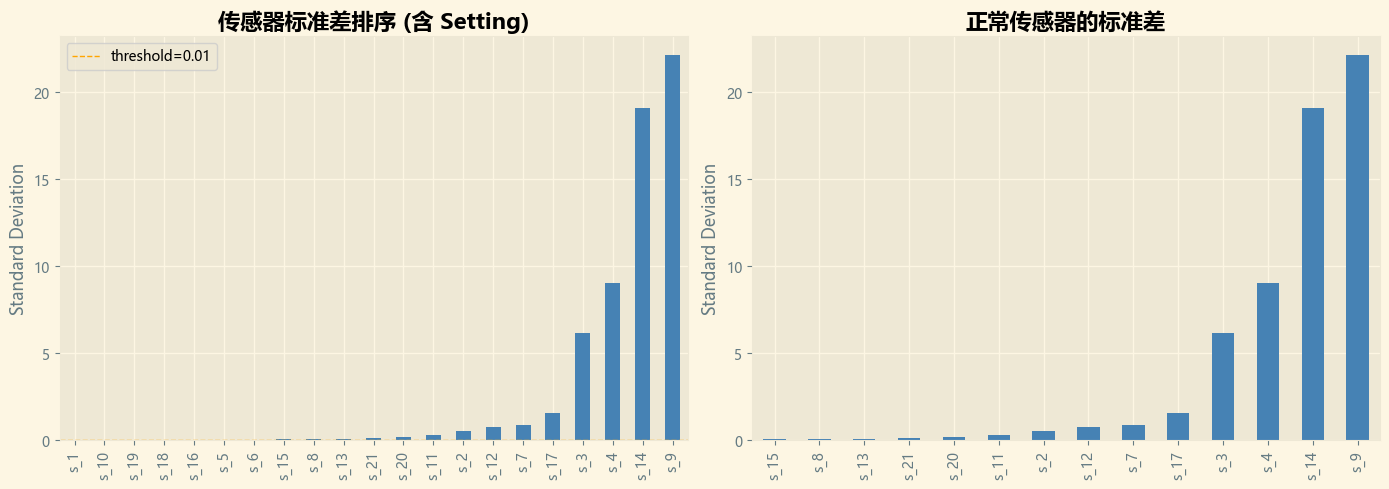

In [220]:
# 4. 传感器方差可视化
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 全部传感器 std 排序
ax = axes[0]
colors = ['red' if s in zero_var else 'orange' if s in low_var else 'steelblue' for s in sensor_std.index]
sensor_std.plot(kind='bar', ax=ax, color=colors)
ax.set_title('传感器标准差排序 (含 Setting)', fontweight='bold')
ax.set_ylabel('Standard Deviation')
ax.axhline(y=0.01, color='orange', linestyle='--', linewidth=1, label='threshold=0.01')
ax.legend()

# 只看正常传感器
ax2 = axes[1]
normal_std = sensor_std[normal]
normal_std.plot(kind='bar', ax=ax2, color='steelblue')
ax2.set_title('正常传感器的标准差', fontweight='bold')
ax2.set_ylabel('Standard Deviation')

plt.tight_layout()
plt.show()

## 运行工况 (Operational Regime) 分析

In [221]:
# 1. 查看 setting 的唯一组合
print('=== Setting 列唯一值数量 ===')
for col in ['setting_1', 'setting_2', 'setting_3']:
    print(f'{col}: {train[col].nunique()} unique values, values={sorted(train[col].dropna().unique())}')

# 找出所有 (setting_1, setting_2, setting_3) 的组合
setting_combo = train[['setting_1', 'setting_2', 'setting_3']].drop_duplicates().sort_values(['setting_1', 'setting_2'])
print(f'\n=== 运行工况组合 (共 {len(setting_combo)} 种) ===')
print(setting_combo.to_string(index=False))

=== Setting 列唯一值数量 ===
setting_1: 158 unique values, values=[np.float64(-0.0087), np.float64(-0.0086), np.float64(-0.0084), np.float64(-0.0081), np.float64(-0.0078), np.float64(-0.0075), np.float64(-0.0074), np.float64(-0.0073), np.float64(-0.0072), np.float64(-0.007), np.float64(-0.0069), np.float64(-0.0068), np.float64(-0.0067), np.float64(-0.0066), np.float64(-0.0065), np.float64(-0.0064), np.float64(-0.0063), np.float64(-0.0062), np.float64(-0.0061), np.float64(-0.006), np.float64(-0.0059), np.float64(-0.0058), np.float64(-0.0057), np.float64(-0.0056), np.float64(-0.0055), np.float64(-0.0054), np.float64(-0.0053), np.float64(-0.0052), np.float64(-0.0051), np.float64(-0.005), np.float64(-0.0049), np.float64(-0.0048), np.float64(-0.0047), np.float64(-0.0046), np.float64(-0.0045), np.float64(-0.0044), np.float64(-0.0043), np.float64(-0.0042), np.float64(-0.0041), np.float64(-0.004), np.float64(-0.0039), np.float64(-0.0038), np.float64(-0.0037), np.float64(-0.0036), np.float64(-0.0035)

In [222]:
# 2. 每个工况组合下的发动机数量和运行时长分布
# 先给 train 添加工况标签
train['regime'] = train['setting_1'].astype(str) + '_' + train['setting_2'].astype(str)

# 每台发动机属于哪个工况（取最常见的那个）
engine_regime = train.groupby('unit_number')['regime'].agg(lambda x: x.mode().iloc[0] if not x.mode().empty else x.iloc[0])

# 每个工况的发动机数量
regime_counts = engine_regime.value_counts()
print('=== 各工况下的发动机数量 ===')
print(regime_counts)

# 每个工况下发动机的平均寿命
engine_life = train.groupby('unit_number')['time_cycles'].max()
engine_regime_life = pd.DataFrame({'regime': engine_regime, 'life': engine_life})
print('\n=== 各工况下发动机寿命统计 ===')
print(engine_regime_life.groupby('regime')['life'].describe())

=== 各工况下的发动机数量 ===
regime
0.0001_-0.0002     3
-0.0001_-0.0001    3
-0.0006_-0.0002    3
-0.0003_0.0001     3
-0.0007_0.0002     2
                  ..
-0.0007_-0.0004    1
0.0009_-0.0001     1
-0.0006_0.0001     1
-0.0025_-0.0001    1
-0.0009_-0.0003    1
Name: count, Length: 85, dtype: int64

=== 各工况下发动机寿命统计 ===
                 count   mean        std    min    25%    50%    75%    max
regime                                                                     
-0.0001_-0.0001    3.0  219.0  51.971146  180.0  189.5  199.0  238.5  278.0
-0.0001_0.0002     1.0  216.0        NaN  216.0  216.0  216.0  216.0  216.0
-0.0001_0.0003     1.0  147.0        NaN  147.0  147.0  147.0  147.0  147.0
-0.0001_0.0005     1.0  165.0        NaN  165.0  165.0  165.0  165.0  165.0
-0.0002_-0.0002    1.0  213.0        NaN  213.0  213.0  213.0  213.0  213.0
...                ...    ...        ...    ...    ...    ...    ...    ...
0.0019_-0.0003     1.0  178.0        NaN  178.0  178.0  178.0  178.0  178.0


## 传感器退化趋势分析

C:\Users\HP\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\HP\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


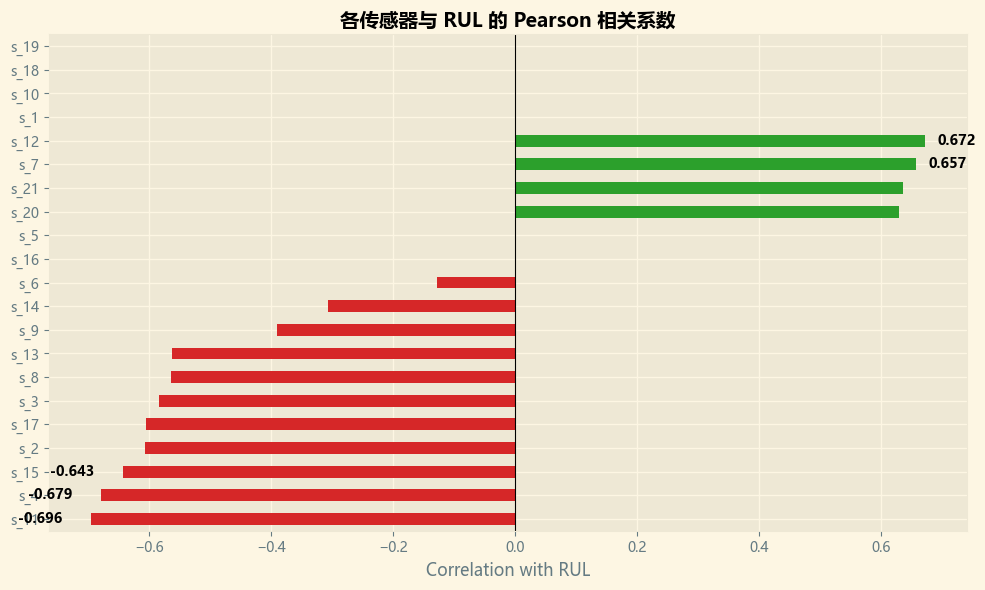

📈 与RUL正相关 (RUL↑传感器值↑, 即故障前下降): ['s_5', 's_20', 's_21', 's_7', 's_12']
📉 与RUL负相关 (RUL↓传感器值↑, 即故障前上升): ['s_11', 's_4', 's_15', 's_2', 's_17', 's_3', 's_8', 's_13', 's_9', 's_14', 's_6', 's_16']


In [223]:
# 1. 各传感器与 RUL 的相关性（基于清洗后数据）
sensor_cols_clean = [c for c in train.columns if c.startswith('s_')]
sensor_rul_corr = train[sensor_cols_clean].corrwith(train['RUL']).sort_values()

fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#d62728' if v < 0 else '#2ca02c' for v in sensor_rul_corr.values]
sensor_rul_corr.plot(kind='barh', ax=ax, color=colors)
ax.axvline(x=0, color='black', linewidth=0.8)
ax.set_title('各传感器与 RUL 的 Pearson 相关系数', fontweight='bold', fontsize=14)
ax.set_xlabel('Correlation with RUL')
# 标注绝对值最大的前5个
top5 = sensor_rul_corr.abs().nlargest(5).index
for s in top5:
    ax.text(sensor_rul_corr[s] + (0.02 if sensor_rul_corr[s] > 0 else -0.12),
            sensor_rul_corr.index.get_loc(s),
            f'{sensor_rul_corr[s]:.3f}', va='center', fontweight='bold', fontsize=10)
plt.tight_layout()
plt.show()

# 分组：与RUL正相关 vs 负相关
pos_corr = sensor_rul_corr[sensor_rul_corr > 0].index.tolist()
neg_corr = sensor_rul_corr[sensor_rul_corr < 0].index.tolist()
print(f'📈 与RUL正相关 (RUL↑传感器值↑, 即故障前下降): {pos_corr}')
print(f'📉 与RUL负相关 (RUL↓传感器值↑, 即故障前上升): {neg_corr}')

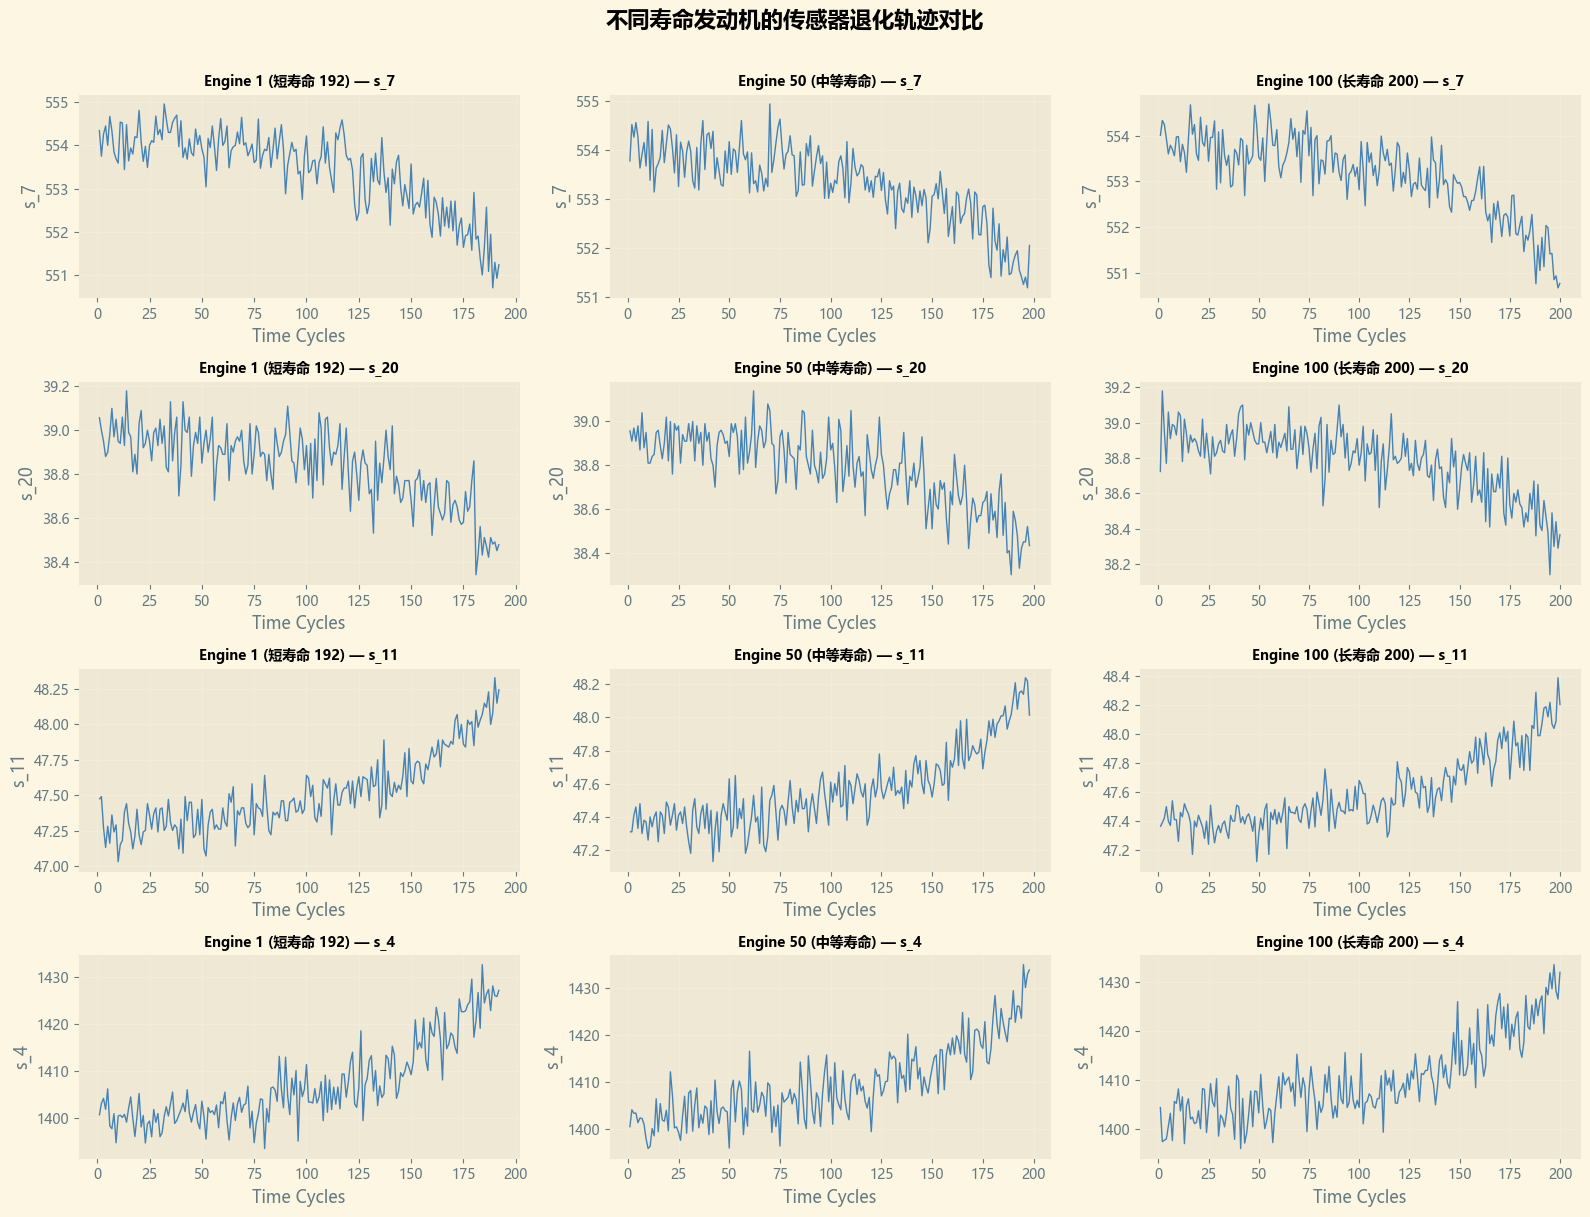

In [224]:
# 2. 单个发动机的传感器时间序列 —— 选3台不同寿命的发动机
engines_short  = train[train['unit_number'].isin([1])]          # 192 cycles
engines_mid    = train[train['unit_number'].isin([50])]         # 中等寿命
engines_long   = train[train['unit_number'].isin([100])]        # 200 cycles

# 挑4个代表性传感器：正相关代表(s_7, s_20) + 负相关代表(s_11, s_4)
demo_sensors = ['s_7', 's_20', 's_11', 's_4']
demo_engines = [(1, engines_short, '短寿命 192'),
                (50, engines_mid, '中等寿命'),
                (100, engines_long, '长寿命 200')]

fig, axes = plt.subplots(len(demo_sensors), len(demo_engines), figsize=(16, 12))
for col_idx, (unit, data, label) in enumerate(demo_engines):
    for row_idx, sensor in enumerate(demo_sensors):
        ax = axes[row_idx, col_idx]
        ax.plot(data['time_cycles'], data[sensor], linewidth=1, color='steelblue')
        ax.set_title(f'Engine {unit} ({label}) — {sensor}', fontsize=10, fontweight='bold')
        ax.set_xlabel('Time Cycles')
        ax.set_ylabel(sensor)
        ax.grid(True, alpha=0.3)

plt.suptitle('不同寿命发动机的传感器退化轨迹对比', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

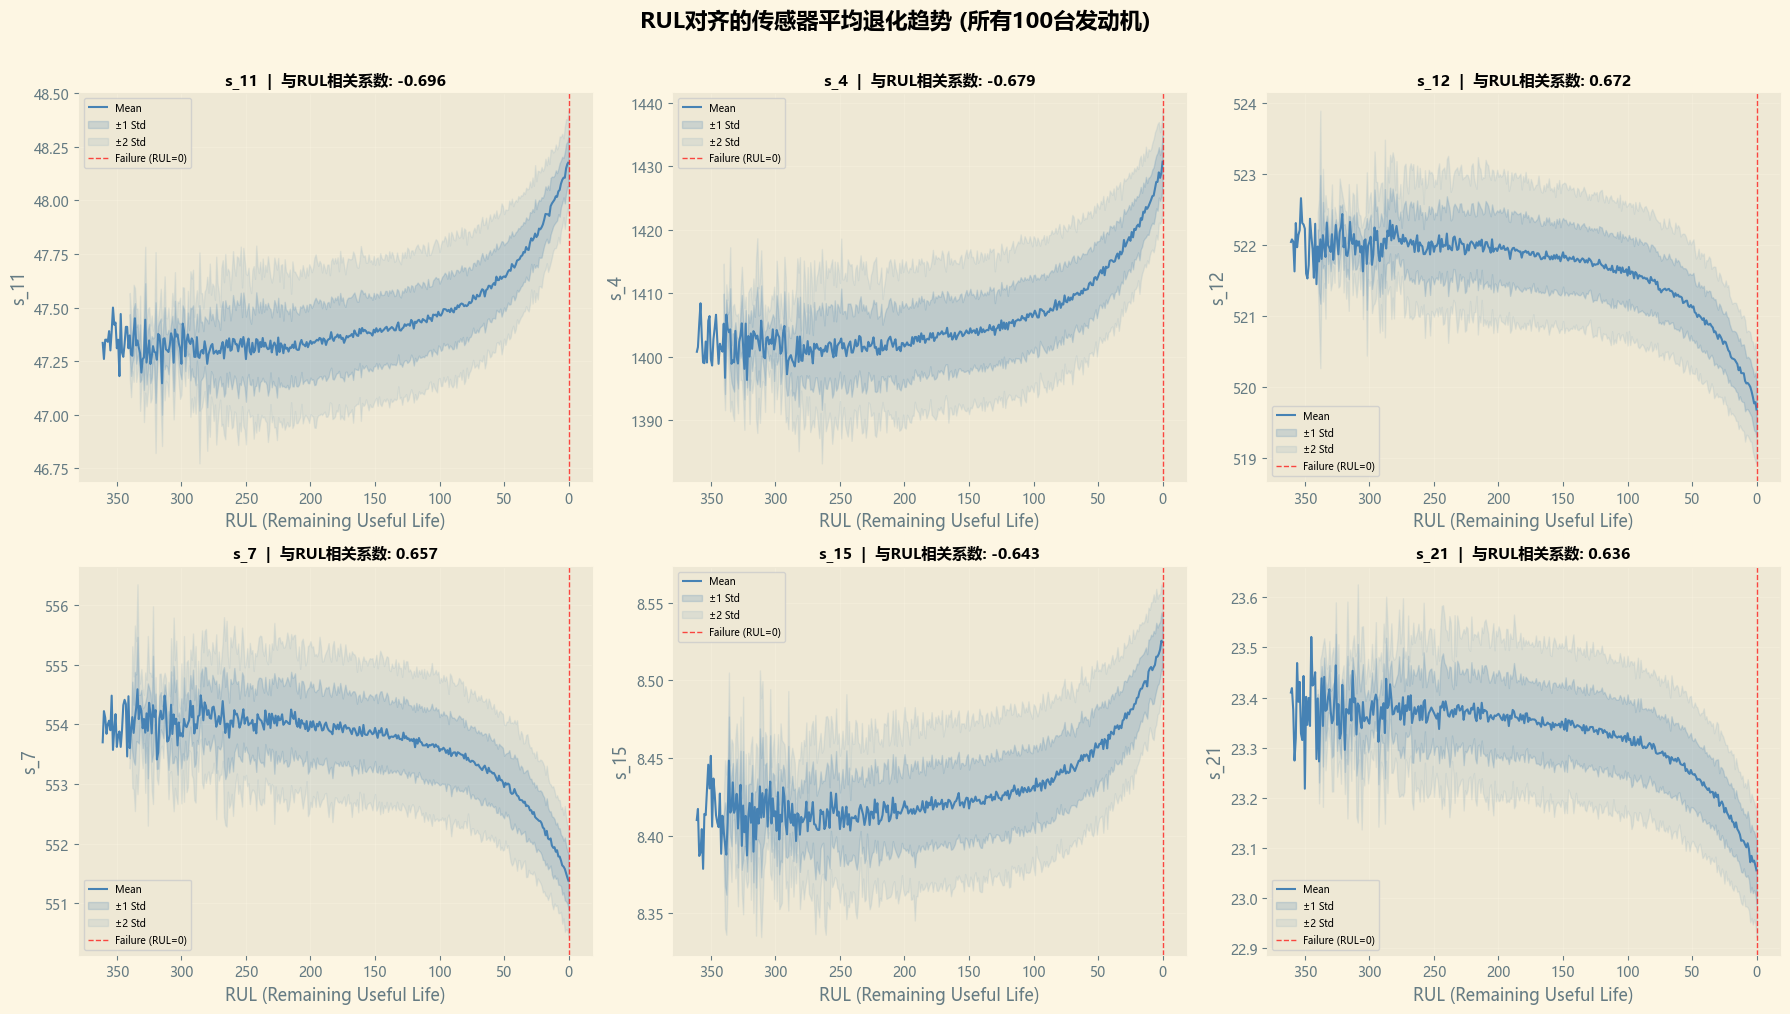

解读要点：
• 均值曲线在接近RUL=0(故障)时是否呈现显著趋势 → 该传感器是良好的退化指示器
• 阴影带宽度 → 发动机间一致性。带越窄，该传感器退化模式越稳定
• 如果曲线平坦且阴影宽 → 该传感器可能受噪声/工况影响大，不一定适合做特征


In [225]:
# 3. 【核心图】RUL对齐的传感器平均退化趋势 —— 所有发动机按剩余寿命对齐
# 这是预测性维护EDA最重要的图：观察传感器在故障前是否呈现一致的退化趋势

# 选取与RUL相关性最高的6个传感器
top6_sensors = sensor_rul_corr.abs().nlargest(6).index.tolist()

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for idx, sensor in enumerate(top6_sensors):
    ax = axes[idx]
    # 对每个RUL值，计算所有发动机在该时刻的该传感器均值和标准差
    rul_stats = train.groupby('RUL')[sensor].agg(['mean', 'std']).sort_index(ascending=False)
    
    x = rul_stats.index
    mean = rul_stats['mean']
    std  = rul_stats['std']
    
    ax.plot(x, mean, linewidth=1.5, color='steelblue', label='Mean')
    ax.fill_between(x, mean - std, mean + std, alpha=0.2, color='steelblue', label='±1 Std')
    ax.fill_between(x, mean - 2*std, mean + 2*std, alpha=0.1, color='steelblue', label='±2 Std')
    ax.axvline(x=0, color='red', linestyle='--', linewidth=1, alpha=0.7, label='Failure (RUL=0)')
    
    corr_val = sensor_rul_corr[sensor]
    ax.set_title(f'{sensor}  |  与RUL相关系数: {corr_val:.3f}', fontsize=11, fontweight='bold')
    ax.set_xlabel('RUL (Remaining Useful Life)')
    ax.set_ylabel(sensor)
    ax.invert_xaxis()  # RUL从大到小，故障点在右侧
    ax.legend(loc='best', fontsize=7)
    ax.grid(True, alpha=0.3)

plt.suptitle('RUL对齐的传感器平均退化趋势 (所有100台发动机)', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

print('解读要点：')
print('• 均值曲线在接近RUL=0(故障)时是否呈现显著趋势 → 该传感器是良好的退化指示器')
print('• 阴影带宽度 → 发动机间一致性。带越窄，该传感器退化模式越稳定')
print('• 如果曲线平坦且阴影宽 → 该传感器可能受噪声/工况影响大，不一定适合做特征')

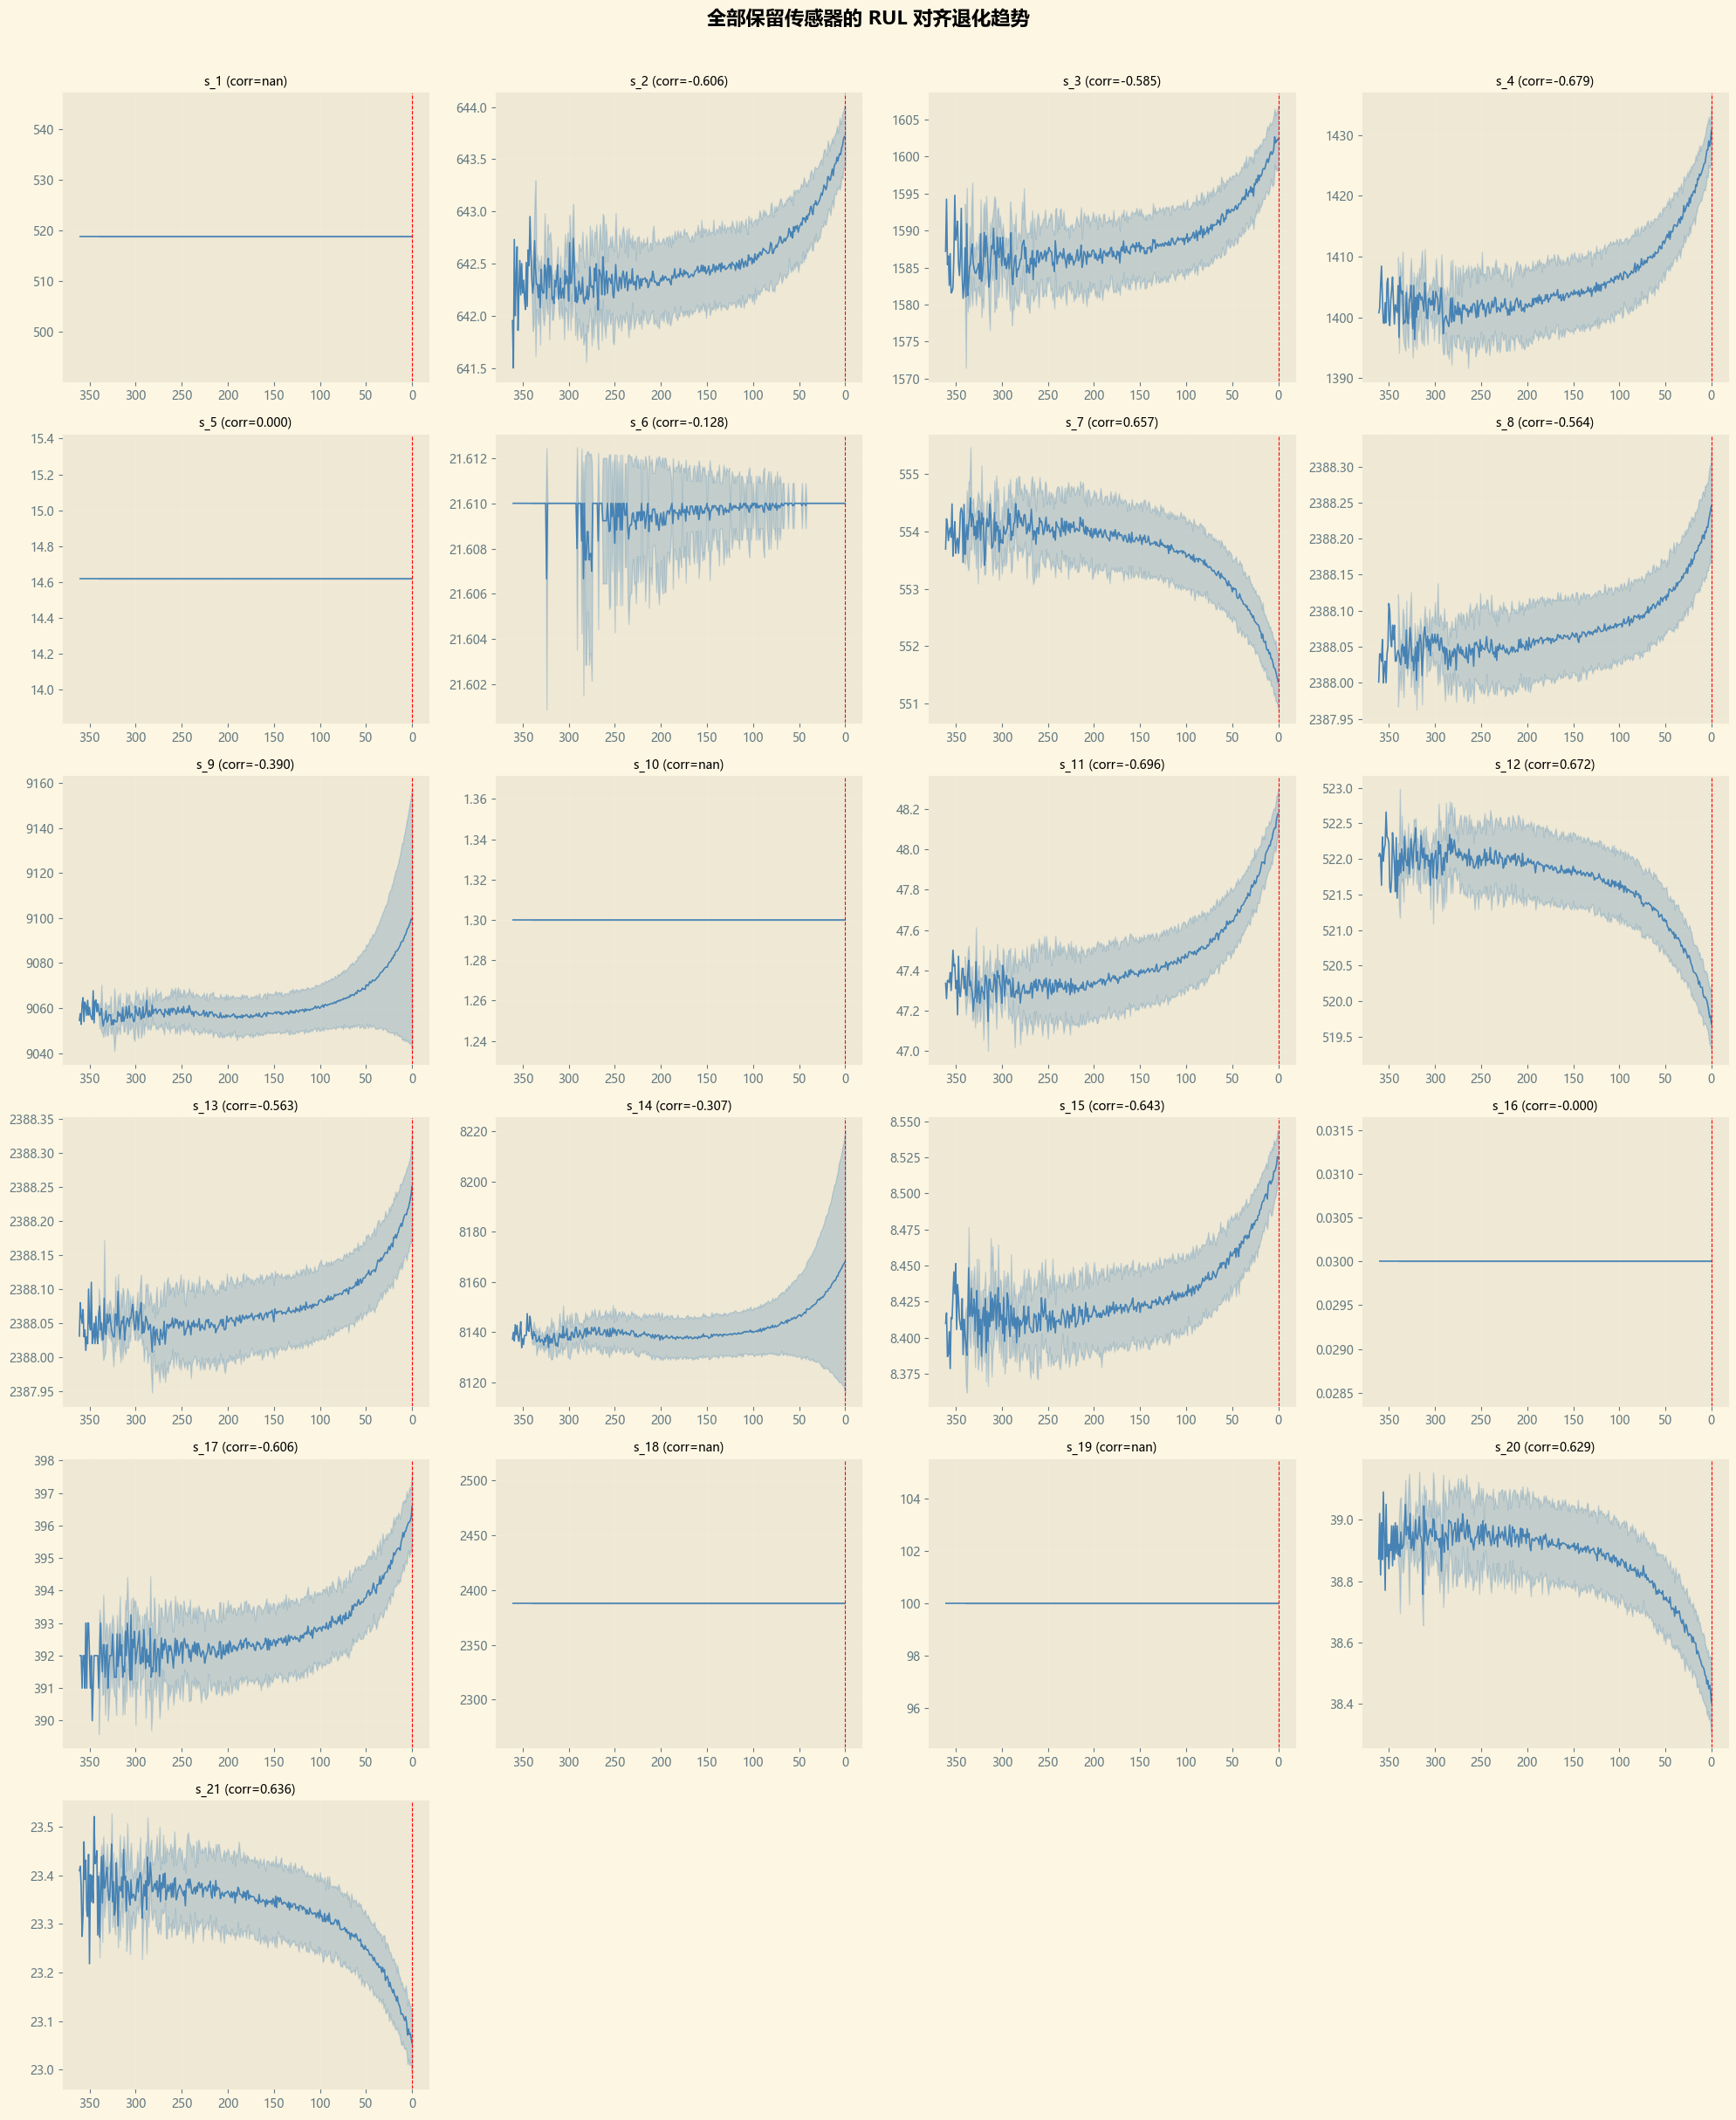

In [226]:
# 4. 全部保留传感器的 RUL 对齐趋势总览
sensor_cols_clean = [c for c in train.columns if c.startswith('s_')]
n_sensors = len(sensor_cols_clean)
n_cols = 4
n_rows = (n_sensors + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))
axes = axes.flatten()

for idx, sensor in enumerate(sensor_cols_clean):
    ax = axes[idx]
    rul_stats = train.groupby('RUL')[sensor].agg(['mean', 'std']).sort_index(ascending=False)
    x = rul_stats.index
    mean = rul_stats['mean']
    std  = rul_stats['std']
    
    ax.plot(x, mean, linewidth=1.2, color='steelblue')
    ax.fill_between(x, mean - std, mean + std, alpha=0.25, color='steelblue')
    ax.axvline(x=0, color='red', linestyle='--', linewidth=0.8)
    ax.set_title(f'{sensor} (corr={sensor_rul_corr[sensor]:.3f})', fontsize=10)
    ax.invert_xaxis()
    ax.grid(True, alpha=0.2)

# 隐藏多余的子图
for idx in range(n_sensors, len(axes)):
    axes[idx].set_visible(False)

plt.suptitle('全部保留传感器的 RUL 对齐退化趋势', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

In [227]:
# 5. 退化趋势分类总结
# 根据相关性和RUL趋势图，将传感器分为三类

# 标准差归一化: 计算每个传感器在RUL<30(故障临近区) vs RUL>100(健康区)的均值差异
late_rul = train[train['RUL'] <= 30]
early_rul = train[train['RUL'] > 100]

degradation_summary = []
for s in sensor_cols_clean:
    early_mean = early_rul[s].mean()
    late_mean  = late_rul[s].mean()
    # 变化率 = (末期 - 早期) / 早期
    change_pct = (late_mean - early_mean) / (abs(early_mean) + 1e-8) * 100
    degradation_summary.append({
        'sensor': s,
        'corr_RUL': sensor_rul_corr[s],
        'early_mean': early_mean,
        'late_mean': late_mean,
        'change_pct': change_pct,
        'trend': '↑ 故障前上升' if change_pct > 2 else '↓ 故障前下降' if change_pct < -2 else '→ 变化不显著'
    })

degrad_df = pd.DataFrame(degradation_summary).set_index('sensor')
degrad_df = degrad_df.sort_values('change_pct', key=abs, ascending=False)

print('=== 传感器退化强度排序 (按故障临近期 vs 健康期的变化幅度) ===')
print(degrad_df.to_string())

# 建议
strong_signals = degrad_df[abs(degrad_df['change_pct']) > 5].index.tolist()
weak_signals   = degrad_df[abs(degrad_df['change_pct']) <= 2].index.tolist()
print(f'\n💪 强退化信号 (变化>5%): {strong_signals}')
print(f'🤔 弱退化信号 (变化≤2%): {weak_signals}')
print(f'📌 建议：{len(strong_signals)}个传感器退化趋势明显，优先作为特征；弱信号传感器仍需保留（可能携带工况信息或交互效应）')

=== 传感器退化强度排序 (按故障临近期 vs 健康期的变化幅度) ===
            corr_RUL   early_mean    late_mean    change_pct    trend
sensor                                                               
s_4    -6.789482e-01  1403.748882  1422.811913  1.358009e+00  → 变化不显著
s_11   -6.962281e-01    47.383485    47.963948  1.225033e+00  → 变化不显著
s_21    6.356620e-01    23.347914    23.133585 -9.179810e-01  → 变化不显著
s_20    6.294285e-01    38.913625    38.558419 -9.128066e-01  → 变化不显著
s_15   -6.426670e-01     8.421611     8.497328  8.990833e-01  → 变化不显著
s_17   -6.061536e-01   392.408223   395.358065  7.517277e-01  → 变化不显著
s_3    -5.845204e-01  1587.491078  1598.715435  7.070501e-01  → 变化不显著
s_7     6.572227e-01   553.862756   552.050997 -3.271133e-01  → 变化不显著
s_9    -3.901016e-01  9057.810700  9087.274232  3.252832e-01  → 变化不显著
s_12    6.719831e-01   521.833066   520.290668 -2.955732e-01  → 变化不显著
s_14   -3.067689e-01  8138.702232  8159.224410  2.521554e-01  → 变化不显著
s_2    -6.064840e-01   642.422337   643.372297  1.4

## 传感器聚类 & 相关性结构

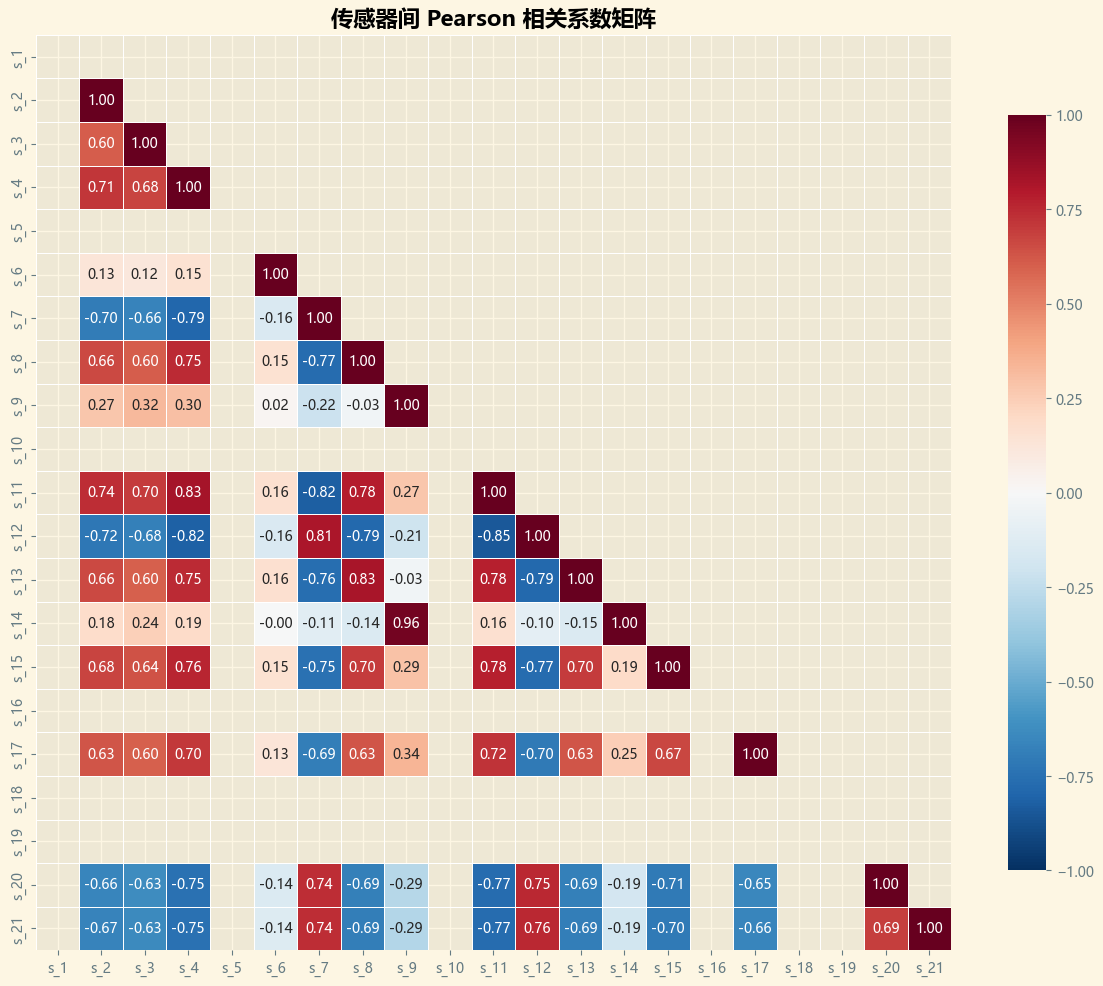

=== 高度相关传感器对 (|r|>0.85) 共 1 对 ===
  s_9 ↔ s_14: r = 0.963


In [228]:
# 1. 传感器相关性热力图 —— 只看保留的传感器列
sensor_cols_clean = [c for c in train.columns if c.startswith('s_')]
corr_matrix = train[sensor_cols_clean].corr()

plt.figure(figsize=(12, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)  # 只显示下三角
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('传感器间 Pearson 相关系数矩阵', fontweight='bold', fontsize=16)
plt.tight_layout()
plt.show()

# 找出高度相关的传感器对 (|r| > 0.85)
high_corr_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        r = corr_matrix.iloc[i, j]
        if abs(r) > 0.85:
            high_corr_pairs.append((corr_matrix.columns[i], corr_matrix.columns[j], r))

if high_corr_pairs:
    print(f'=== 高度相关传感器对 (|r|>0.85) 共 {len(high_corr_pairs)} 对 ===')
    for s1, s2, r in sorted(high_corr_pairs, key=lambda x: -abs(x[2])):
        print(f'  {s1} ↔ {s2}: r = {r:.3f}')
else:
    print('没有 |r|>0.85 的传感器对 —— 说明传感器间冗余度不高')

参与聚类的传感器 (15个): ['s_2', 's_3', 's_4', 's_6', 's_7', 's_8', 's_9', 's_11', 's_12', 's_13', 's_14', 's_15', 's_17', 's_20', 's_21']


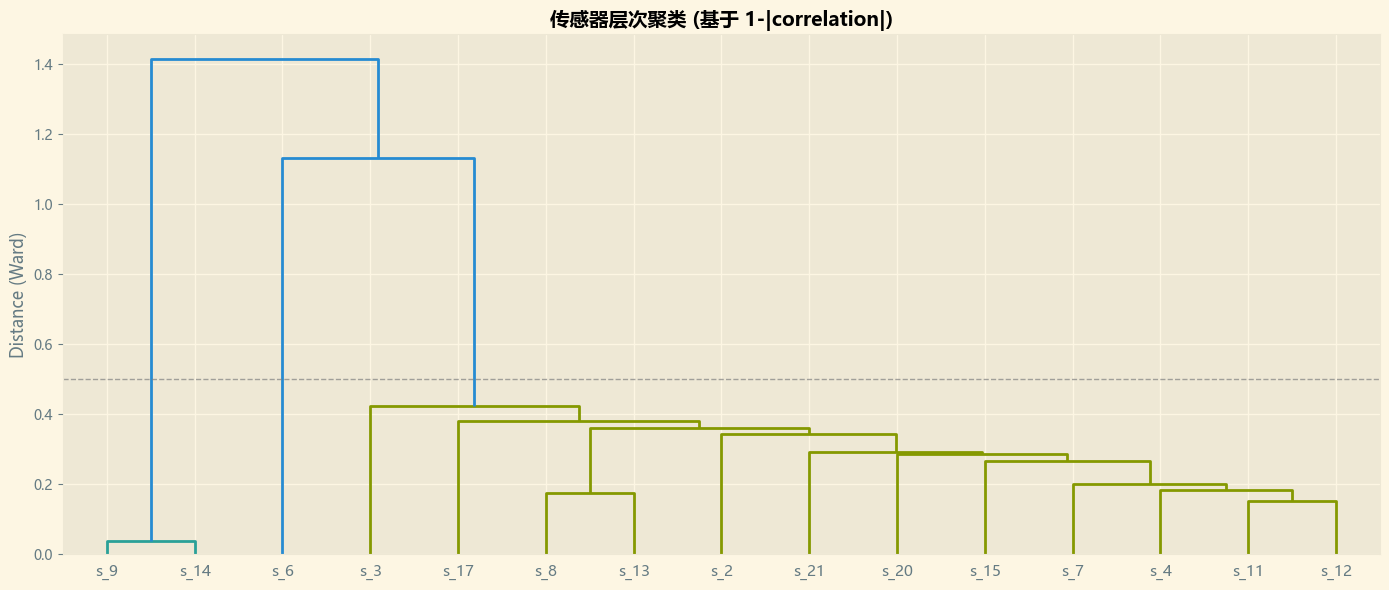

=== 传感器聚类结果 (距离阈值 0.5) ===
  Cluster 1 (2个): ['s_9', 's_14']
  Cluster 2 (12个): ['s_2', 's_3', 's_4', 's_7', 's_8', 's_11', 's_12', 's_13', 's_15', 's_17', 's_20', 's_21']
  Cluster 3 (1个): ['s_6']


In [229]:
# 2. 层次聚类 —— 基于相关性将传感器分组（排除零方差传感器）
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.spatial.distance import squareform

# 只保留有方差的传感器（零方差传感器的 corr 为 NaN，会导致 linkage 报错）
valid_sensors = corr_matrix.dropna(axis=0, how='all').dropna(axis=1, how='all').columns.tolist()
print(f'参与聚类的传感器 ({len(valid_sensors)}个): {valid_sensors}')

corr_valid = corr_matrix.loc[valid_sensors, valid_sensors]

# 距离 = 1 - |correlation|，把正相关和负相关都视为"关联"
dist_matrix = 1 - corr_valid.abs()
condensed_dist = squareform(dist_matrix.values, checks=False)
linkage_matrix = linkage(condensed_dist, method='ward')

fig, ax = plt.subplots(figsize=(14, 6))
dendrogram(linkage_matrix, labels=corr_valid.columns, ax=ax,
           leaf_rotation=0, leaf_font_size=11,
           color_threshold=0.5)  # 距离阈值
ax.axhline(y=0.5, color='gray', linestyle='--', linewidth=1, alpha=0.7)
ax.set_title('传感器层次聚类 (基于 1-|correlation|)', fontweight='bold', fontsize=14)
ax.set_ylabel('Distance (Ward)')
plt.tight_layout()
plt.show()

# 在距离阈值 0.5 处切分，得到传感器簇
labels = fcluster(linkage_matrix, t=0.5, criterion='distance')
sensor_clusters = pd.DataFrame({'sensor': corr_valid.columns, 'cluster': labels})
print('=== 传感器聚类结果 (距离阈值 0.5) ===')
for c in sorted(sensor_clusters['cluster'].unique()):
    members = sensor_clusters[sensor_clusters['cluster'] == c]['sensor'].tolist()
    print(f'  Cluster {c} ({len(members)}个): {members}')

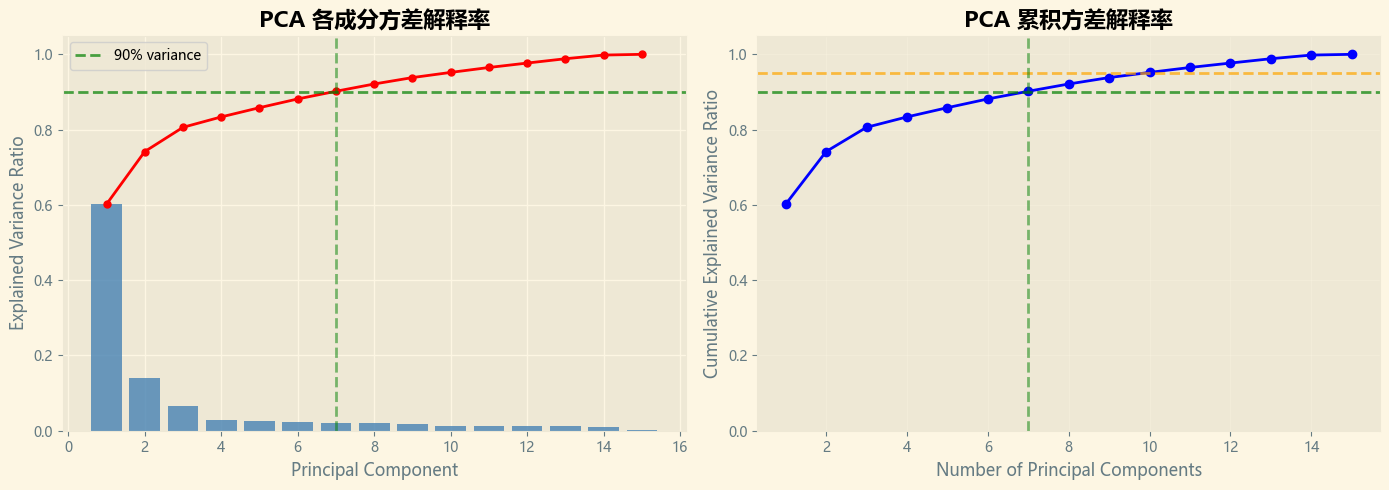

总传感器数（有方差）: 15
前 7 个主成分可解释 90% 方差
  80% 方差 → 3 个PC (20%)
  90% 方差 → 7 个PC (47%)
  95% 方差 → 10 个PC (67%)
  99% 方差 → 14 个PC (93%)


In [230]:
# 3. PCA 分析 —— 评估传感器的有效维度（仅用有方差传感器）
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 使用 valid_sensors（排除零方差的死传感器）
sensor_data_scaled = scaler.fit_transform(train[valid_sensors])

pca = PCA()
pca.fit(sensor_data_scaled)

# 累积方差解释率
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.bar(range(1, len(valid_sensors)+1), pca.explained_variance_ratio_, color='steelblue', alpha=0.8)
ax.plot(range(1, len(valid_sensors)+1), np.cumsum(pca.explained_variance_ratio_),
        'ro-', markersize=5, linewidth=2)
ax.set_title('PCA 各成分方差解释率', fontweight='bold')
ax.set_xlabel('Principal Component')
ax.set_ylabel('Explained Variance Ratio')
ax.axhline(y=0.9, color='green', linestyle='--', alpha=0.7, label='90% variance')
cumsum = np.cumsum(pca.explained_variance_ratio_)
pc90 = np.argmax(cumsum >= 0.9) + 1
ax.axvline(x=pc90, color='green', linestyle='--', alpha=0.5)
ax.legend()

ax2 = axes[1]
ax2.plot(range(1, len(valid_sensors)+1), np.cumsum(pca.explained_variance_ratio_),
         'bo-', markersize=6, linewidth=2)
ax2.set_title('PCA 累积方差解释率', fontweight='bold')
ax2.set_xlabel('Number of Principal Components')
ax2.set_ylabel('Cumulative Explained Variance Ratio')
ax2.axhline(y=0.90, color='green', linestyle='--', alpha=0.7)
ax2.axhline(y=0.95, color='orange', linestyle='--', alpha=0.7)
ax2.axvline(x=pc90, color='green', linestyle='--', alpha=0.5)
ax2.set_ylim(0, 1.05)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f'总传感器数（有方差）: {len(valid_sensors)}')
print(f'前 {pc90} 个主成分可解释 90% 方差')
for threshold in [0.80, 0.90, 0.95, 0.99]:
    n = np.argmax(cumsum >= threshold) + 1
    print(f'  {threshold:.0%} 方差 → {n} 个PC ({n/len(valid_sensors)*100:.0f}%)')

In [231]:
# 4. 综合总结：传感器分组 + 退化信号 + 降维潜力
print('=' * 70)
print('📊 传感器分析综合结论')
print('=' * 70)

print(f'\n🔢 原始传感器: 21个')
print(f'🗑️  剔除零/低方差: {len(sensor_std) - len(valid_sensors)}个 ({[s for s in sensor_std.index if s not in valid_sensors]})')
print(f'✅ 有效传感器: {len(valid_sensors)}个')
print(f'📦 聚类数: {sensor_clusters["cluster"].nunique()} 个传感器簇')
print(f'🎯 前 {pc90} 个PC解释90%方差 → 有效维度约为原始的 {pc90/len(valid_sensors)*100:.0f}%')

# 每个簇与RUL的平均相关性
print('\n--- 各传感器簇与 RUL 的关系 ---')
for c in sorted(sensor_clusters['cluster'].unique()):
    members = sensor_clusters[sensor_clusters['cluster'] == c]['sensor'].tolist()
    avg_corr = sensor_rul_corr[members].abs().mean()
    signs = sensor_rul_corr[members].apply(lambda x: '+' if x > 0 else '-').value_counts()
    dominant = signs.idxmax() if len(signs) > 0 else '?'
    print(f'  Cluster {c} ({len(members)}个): {members}')
    print(f'         avg|corr_RUL| = {avg_corr:.3f}, 主导相关方向: {dominant}')

print('\n📌 建模建议:')
print('  1. 若使用树模型(XGBoost/LightGBM): 保留全部传感器，模型自行处理冗余')
print('  2. 若使用线性模型: 考虑PCA降维或从每个簇中选代表传感器')
print('  3. 若做特征工程: 每个簇的均值/趋势可作为衍生特征')

📊 传感器分析综合结论

🔢 原始传感器: 21个
🗑️  剔除零/低方差: 6个 (['s_1', 's_10', 's_19', 's_18', 's_16', 's_5'])
✅ 有效传感器: 15个
📦 聚类数: 3 个传感器簇
🎯 前 7 个PC解释90%方差 → 有效维度约为原始的 47%

--- 各传感器簇与 RUL 的关系 ---
  Cluster 1 (2个): ['s_9', 's_14']
         avg|corr_RUL| = 0.348, 主导相关方向: -
  Cluster 2 (12个): ['s_2', 's_3', 's_4', 's_7', 's_8', 's_11', 's_12', 's_13', 's_15', 's_17', 's_20', 's_21']
         avg|corr_RUL| = 0.628, 主导相关方向: -
  Cluster 3 (1个): ['s_6']
         avg|corr_RUL| = 0.128, 主导相关方向: -

📌 建模建议:
  1. 若使用树模型(XGBoost/LightGBM): 保留全部传感器，模型自行处理冗余
  2. 若使用线性模型: 考虑PCA降维或从每个簇中选代表传感器
  3. 若做特征工程: 每个簇的均值/趋势可作为衍生特征


## RUL 分布 & 截断分析

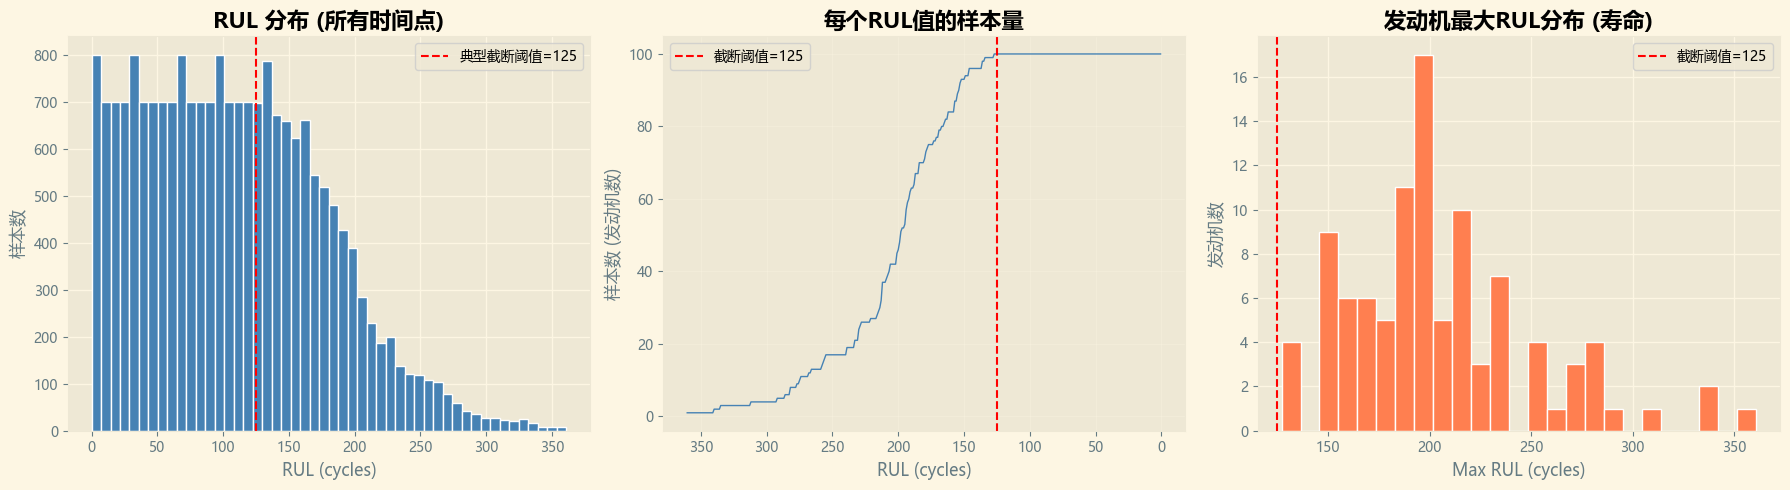

RUL 范围: 0 ~ 361 cycles
发动机寿命范围: 127 ~ 361 cycles
RUL > 125 的样本占比: 38.9%


In [232]:
# 1. RUL 分布概览
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 左: RUL 直方图
ax = axes[0]
train['RUL'].hist(bins=50, ax=ax, color='steelblue', edgecolor='white')
ax.axvline(x=125, color='red', linestyle='--', linewidth=1.5, label='典型截断阈值=125')
ax.set_title('RUL 分布 (所有时间点)', fontweight='bold')
ax.set_xlabel('RUL (cycles)')
ax.set_ylabel('样本数')
ax.legend()

# 中: 每个RUL值对应的样本量（发动机数量随RUL增大而减少）
ax2 = axes[1]
rul_sample_count = train.groupby('RUL').size()
rul_sample_count.plot(ax=ax2, color='steelblue', linewidth=1)
ax2.axvline(x=125, color='red', linestyle='--', linewidth=1.5, label='截断阈值=125')
ax2.set_title('每个RUL值的样本量', fontweight='bold')
ax2.set_xlabel('RUL (cycles)')
ax2.set_ylabel('样本数 (发动机数)')
ax2.invert_xaxis()
ax2.legend()
ax2.grid(True, alpha=0.3)

# 右: 发动机寿命分布（每台发动机的最大RUL）
ax3 = axes[2]
engine_max_rul = train.groupby('unit_number')['RUL'].max()
engine_max_rul.hist(bins=25, ax=ax3, color='coral', edgecolor='white')
ax3.axvline(x=125, color='red', linestyle='--', linewidth=1.5, label='截断阈值=125')
ax3.set_title('发动机最大RUL分布 (寿命)', fontweight='bold')
ax3.set_xlabel('Max RUL (cycles)')
ax3.set_ylabel('发动机数')
ax3.legend()

plt.tight_layout()
plt.show()

print(f'RUL 范围: {train["RUL"].min():.0f} ~ {train["RUL"].max():.0f} cycles')
print(f'发动机寿命范围: {engine_max_rul.min():.0f} ~ {engine_max_rul.max():.0f} cycles')
print(f'RUL > 125 的样本占比: {(train["RUL"] > 125).mean()*100:.1f}%')

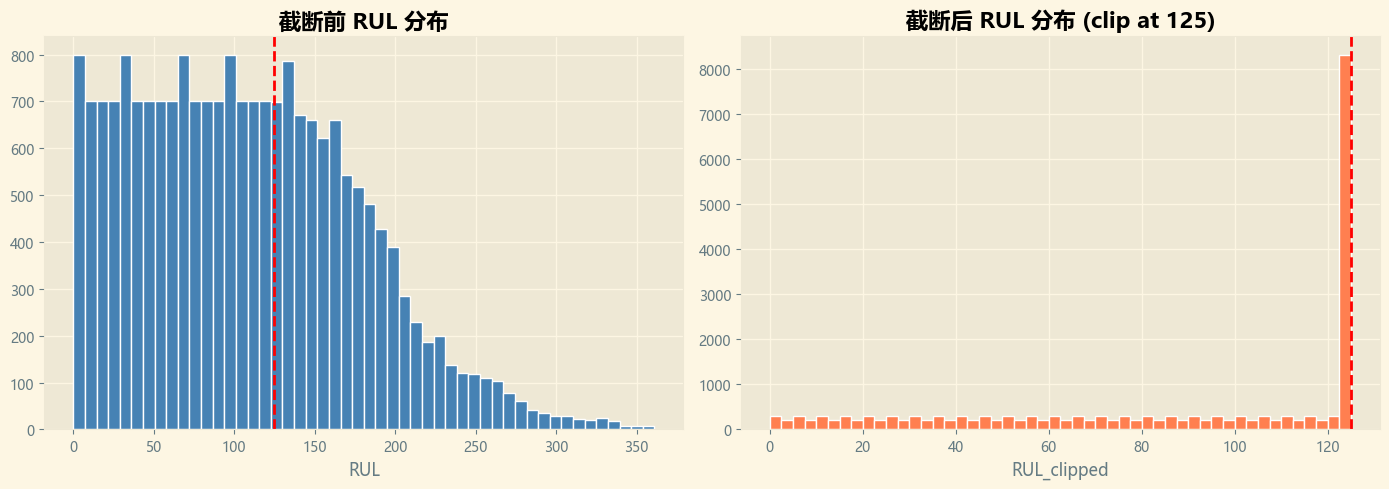

截断阈值: 125 cycles
受影响样本: 8031 条 (38.9%)
截断后 RUL 范围: 0 ~ 125

Valid RUL 截断前: min=7, max=145
Valid RUL 截断后: min=7, max=125


In [233]:
# 2. RUL 截断 (Clipping) —— 预测性维护的标配操作
# 为什么截断？
# - 发动机早期（RUL很大时）传感器几乎无退化信号，此时预测RUL没有意义
# - 让模型聚焦在"危险区"（失效前N个cycle内），提升预测精度
# - CMAPSS 文献中最常用的截断值是 125 或 130

RUL_CLIP = 125
train['RUL_clipped'] = train['RUL'].clip(upper=RUL_CLIP)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 左: 截断前
ax = axes[0]
train['RUL'].hist(bins=50, ax=ax, color='steelblue', edgecolor='white')
ax.axvline(x=RUL_CLIP, color='red', linestyle='--', linewidth=2)
ax.set_title(f'截断前 RUL 分布', fontweight='bold')
ax.set_xlabel('RUL')

# 右: 截断后
ax2 = axes[1]
train['RUL_clipped'].hist(bins=50, ax=ax2, color='coral', edgecolor='white')
ax2.axvline(x=RUL_CLIP, color='red', linestyle='--', linewidth=2)
ax2.set_title(f'截断后 RUL 分布 (clip at {RUL_CLIP})', fontweight='bold')
ax2.set_xlabel('RUL_clipped')

plt.tight_layout()
plt.show()

print(f'截断阈值: {RUL_CLIP} cycles')
print(f'受影响样本: {(train["RUL"] > RUL_CLIP).sum()} 条 ({(train["RUL"] > RUL_CLIP).mean()*100:.1f}%)')
print(f'截断后 RUL 范围: {train["RUL_clipped"].min():.0f} ~ {train["RUL_clipped"].max():.0f}')

# 对 test set 的 RUL 同理需要截断
y_valid_clipped = y_valid['RUL'].clip(upper=RUL_CLIP)
print(f'\nValid RUL 截断前: min={y_valid["RUL"].min():.0f}, max={y_valid["RUL"].max():.0f}')
print(f'Valid RUL 截断后: min={y_valid_clipped.min():.0f}, max={y_valid_clipped.max():.0f}')

C:\Users\HP\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\HP\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


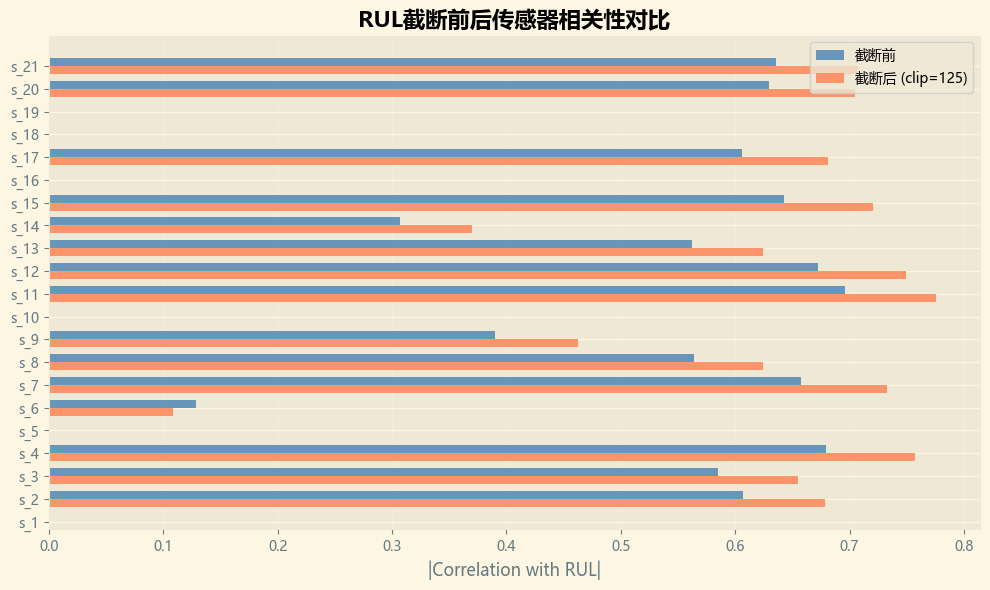

=== 截断后 |corr| 提升最大的传感器 ===
s_11    0.079002
s_4     0.078209
s_15    0.078191
s_12    0.076887
s_7     0.075798
s_20    0.075197


In [234]:
# 3. 截断对传感器-RUL 相关性的影响 —— 截断后相关性通常会增强
corr_before = train[sensor_cols_clean].corrwith(train['RUL']).abs()
corr_after  = train[sensor_cols_clean].corrwith(train['RUL_clipped']).abs()

fig, ax = plt.subplots(figsize=(10, 6))
x = range(len(corr_before))
width = 0.35
ax.barh([i + width/2 for i in x], corr_before.values, width, label='截断前', color='steelblue', alpha=0.8)
ax.barh([i - width/2 for i in x], corr_after.values, width, label='截断后 (clip=125)', color='coral', alpha=0.8)
ax.set_yticks(x)
ax.set_yticklabels(corr_before.index)
ax.set_xlabel('|Correlation with RUL|')
ax.set_title('RUL截断前后传感器相关性对比', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

# 量化提升
improvement = (corr_after - corr_before)
print('=== 截断后 |corr| 提升最大的传感器 ===')
print(improvement.sort_values(ascending=False).head(6).to_string())

## 特征工程

In [235]:
# ============================================================================
# 特征工程总体说明
# ============================================================================
# 基于前6阶段EDA的发现，设计以下5类特征：
#
# 发现1: 原始传感器信号噪声大，RUL对齐图中±1σ带很宽
#   → 特征A: 滑动窗口统计量（去噪、捕捉局部趋势）
#
# 发现2: 退化幅度小（<2%），但方向一致——故障前持续缓慢漂移
#   → 特征B: 窗口线性趋势（斜率）——退化最重要的是"方向"而非"绝对值"
#
# 发现3: 传感器在故障临近区(RUL<30)的变化加速
#   → 特征C: 短窗口 vs 长窗口的变化率比值（捕捉加速退化）
#
# 发现4: 工况每cycle都在变，传感器读数受工况影响
#   → 特征D: 传感器相对于当前工况下"正常值"的偏离（残差）
#
# 发现5: 14个传感器聚为两大对抗集团，相关性结构清晰
#   → 特征E: 传感器集团间的比值特征（放大退化信号）
# ============================================================================

# 定义特征工程使用的传感器（排除零/低方差的死传感器）
FEATURE_SENSORS = valid_sensors  # 来自传感器聚类阶段，15个有方差传感器
WINDOWS = [5, 10, 20, 30]        # 滑动窗口大小（cycles）

print(f'用于特征工程的传感器 ({len(FEATURE_SENSORS)}个): {FEATURE_SENSORS}')
print(f'滑动窗口: {WINDOWS}')

用于特征工程的传感器 (15个): ['s_2', 's_3', 's_4', 's_6', 's_7', 's_8', 's_9', 's_11', 's_12', 's_13', 's_14', 's_15', 's_17', 's_20', 's_21']
滑动窗口: [5, 10, 20, 30]


In [236]:
# ============================================================================
# 特征A: 滑动窗口统计量
# 依据: EDA发现原始传感器噪声大（RUL对齐图中±1σ带很宽），
#       滚动统计可以平滑噪声、捕获局部退化趋势
# 方法: 对每个传感器在每个窗口大小下计算 rolling mean, std, min, max
# ============================================================================
def make_rolling_features(df, sensors, windows):
    """为每个传感器计算滑动窗口统计量"""
    features = pd.DataFrame()
    for sensor in sensors:
        for w in windows:
            roll = df.groupby('unit_number')[sensor].rolling(window=w, min_periods=1)
            features[f'{sensor}_roll_mean_{w}'] = roll.mean().reset_index(level=0, drop=True)
            features[f'{sensor}_roll_std_{w}']  = roll.std().reset_index(level=0, drop=True)
            features[f'{sensor}_roll_min_{w}']  = roll.min().reset_index(level=0, drop=True)
            features[f'{sensor}_roll_max_{w}']  = roll.max().reset_index(level=0, drop=True)
    return features

print('构建滑动窗口统计量...')
rolling_feats = make_rolling_features(train, FEATURE_SENSORS, WINDOWS)
print(f'滑动窗口特征数: {rolling_feats.shape[1]}  ({len(FEATURE_SENSORS)} sensors × {len(WINDOWS)} windows × 4 stats)')

构建滑动窗口统计量...


C:\Users\HP\AppData\Local\Temp\ipykernel_16624\2564744571.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  features[f'{sensor}_roll_mean_{w}'] = roll.mean().reset_index(level=0, drop=True)
C:\Users\HP\AppData\Local\Temp\ipykernel_16624\2564744571.py:14: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  features[f'{sensor}_roll_std_{w}']  = roll.std().reset_index(level=0, drop=True)
C:\Users\HP\AppData\Local\Temp\ipykernel_16624\2564744571.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of c

滑动窗口特征数: 240  (15 sensors × 4 windows × 4 stats)


In [237]:
# ============================================================================
# 特征B: 窗口线性趋势（斜率）
# 依据: EDA发现退化幅度虽小但方向一致。对于预测性维护，
#       "传感器在往哪个方向走"比"传感器当前值是多少"更重要
# 方法: 对每个传感器在滑动窗口内拟合线性回归，取斜率作为特征
# ============================================================================
def make_trend_features(df, sensors, windows):
    """为每个传感器计算滑动窗口内的线性趋势斜率"""
    features = pd.DataFrame()
    for sensor in sensors:
        for w in windows:
            def slope_over_window(x):
                if len(x) < 2:
                    return 0.0
                t = np.arange(len(x))
                slope, _ = np.polyfit(t, x, 1)
                return slope
            trend = df.groupby('unit_number')[sensor].rolling(window=w, min_periods=2).apply(
                slope_over_window, raw=True
            )
            features[f'{sensor}_trend_{w}'] = trend.reset_index(level=0, drop=True)
    return features

print('构建窗口趋势特征...')
trend_feats = make_trend_features(train, FEATURE_SENSORS, WINDOWS)
print(f'趋势特征数: {trend_feats.shape[1]}  ({len(FEATURE_SENSORS)} sensors × {len(WINDOWS)} windows)')

构建窗口趋势特征...
趋势特征数: 60  (15 sensors × 4 windows)


In [238]:
# ============================================================================
# 特征C: 变化率 & 加速退化信号
# 依据: EDA的RUL对齐图中，部分传感器在RUL<50时曲线斜率增大，
#       说明退化在故障临近期加速。短窗口趋势 vs 长窗口趋势的比值
#       可以捕捉这种"加速"
# 方法: 对每个传感器计算 (短窗口均值 - 长窗口均值) / 长窗口均值
# ============================================================================
def make_rate_features(df, sensors):
    """计算短窗口 vs 长窗口的变化率，捕捉加速退化"""
    features = pd.DataFrame()
    for sensor in sensors:
        roll_5  = df.groupby('unit_number')[sensor].rolling(5, min_periods=1).mean().reset_index(level=0, drop=True)
        roll_20 = df.groupby('unit_number')[sensor].rolling(20, min_periods=1).mean().reset_index(level=0, drop=True)
        roll_30 = df.groupby('unit_number')[sensor].rolling(30, min_periods=1).mean().reset_index(level=0, drop=True)
        
        # 短期 vs 长期变化率: 正值=近期上升, 负值=近期下降
        features[f'{sensor}_rate_5v20'] = (roll_5 - roll_20) / (roll_20.abs() + 1e-8)
        features[f'{sensor}_rate_5v30'] = (roll_5 - roll_30) / (roll_30.abs() + 1e-8)
        
        # 变化加速度: 近期趋势 - 远期趋势
        features[f'{sensor}_acc_5v20'] = roll_5 - roll_20  # 绝对差值
    return features

print('构建变化率特征...')
rate_feats = make_rate_features(train, FEATURE_SENSORS)
print(f'变化率特征数: {rate_feats.shape[1]}  ({len(FEATURE_SENSORS)} sensors × 3 ratios)')

构建变化率特征...
变化率特征数: 45  (15 sensors × 3 ratios)


In [239]:
# ============================================================================
# 特征D: 工况归一化残差
# 依据: EDA发现setting_1, setting_2每cycle都变化（100/100台发动机
#       都有工况变化），且85种不同组合。传感器读数不仅反映退化，
#       也受工况影响。去除工况效应后的残差才是"纯退化信号"
# 方法: 对每个(setting_1, setting_2)组合计算传感器均值作为"正常基准"，
#       当前值减去该基准得到残差
# ============================================================================
def make_regime_residual_features(df, sensors):
    """计算传感器相对于其当前工况下均值的偏离（残差）"""
    features = pd.DataFrame()
    # 将连续setting离散化为分箱
    df = df.copy()
    df['s1_bin'] = pd.cut(df['setting_1'], bins=10, labels=False)
    df['s2_bin'] = pd.cut(df['setting_2'], bins=10, labels=False)
    df['regime_bin'] = df['s1_bin'].astype(str) + '_' + df['s2_bin'].astype(str)
    
    # 每个分箱下每个传感器的全局均值（取train所有时间点的均值）
    regime_means = df.groupby('regime_bin')[sensors].transform('mean')
    
    for sensor in sensors:
        # 残差 = 当前值 - 该工况下的均值
        features[f'{sensor}_regime_resid'] = df[sensor] - regime_means[sensor]
    
    # 清理临时列
    return features

print('构建工况残差特征...')
regime_feats = make_regime_residual_features(train, FEATURE_SENSORS)
print(f'工况残差特征数: {regime_feats.shape[1]}  ({len(FEATURE_SENSORS)} sensors)')

构建工况残差特征...
工况残差特征数: 15  (15 sensors)


In [240]:
# ============================================================================
# 特征E: 传感器集团比值
# 依据: EDA聚类结果显示传感器分为两个对抗集团——
#       Group A (正相关RUL): s_7, s_12, s_20, s_21 — 故障前下降
#       Group B (负相关RUL): s_2, s_3, s_4, s_8, s_11, s_13, s_15, s_17 — 故障前上升
#       两个集团的比值会放大退化信号（分子分母朝相反方向走）
# ============================================================================
# 基于传感器聚类和RUL相关性方向定义两个集团
GROUP_RUL_POS = ['s_7', 's_12', 's_20', 's_21']  # 与RUL正相关，故障前下降
GROUP_RUL_NEG = ['s_2', 's_3', 's_4', 's_11', 's_15', 's_17']  # 与RUL负相关，故障前上升

def make_ratio_features(df):
    """计算传感器集团间的比值特征"""
    features = pd.DataFrame()
    # 集团均值
    features['group_pos_mean'] = df[GROUP_RUL_POS].mean(axis=1)  # 正相关组均值
    features['group_neg_mean'] = df[GROUP_RUL_NEG].mean(axis=1)  # 负相关组均值
    # 比值 —— 退化时分子下降、分母上升，比值加速下降
    features['ratio_pos_neg'] = features['group_pos_mean'] / (features['group_neg_mean'] + 1e-8)
    # 对数比值 —— 更稳定的数值分布
    features['log_ratio_pos_neg'] = np.log(features['group_pos_mean'] + 1e-8) - np.log(features['group_neg_mean'] + 1e-8)
    return features

print('构建传感器集团比值特征...')
ratio_feats = make_ratio_features(train)
print(f'比值特征: {list(ratio_feats.columns)}')
print(f'比值特征与RUL的相关系数:')
print(ratio_feats.corrwith(train['RUL']).to_string())

构建传感器集团比值特征...
比值特征: ['group_pos_mean', 'group_neg_mean', 'ratio_pos_neg', 'log_ratio_pos_neg']
比值特征与RUL的相关系数:


group_pos_mean       0.708967
group_neg_mean      -0.710258
ratio_pos_neg        0.727398
log_ratio_pos_neg    0.727388


In [241]:
# ============================================================================
# 特征汇总 & 最终数据集构建
# ============================================================================
# 拼接所有特征
all_features = pd.concat([
    rolling_feats,   # A: 滑动窗口统计量  (15×4×4 = 240)
    trend_feats,     # B: 窗口线性趋势    (15×4   = 60)
    rate_feats,      # C: 变化率/加速     (15×3   = 45)
    regime_feats,    # D: 工况残差        (15     = 15)
    ratio_feats,     # E: 集团比值        (4)
], axis=1)

# 加上原始传感器值和setting作为baseline
base_features = train[FEATURE_SENSORS + ['setting_1', 'setting_2']].copy()
base_features.columns = [f'{c}_raw' if c in FEATURE_SENSORS else c for c in base_features.columns]

all_features = pd.concat([base_features, all_features], axis=1)

print('=' * 60)
print('📊 特征工程汇总')
print('=' * 60)
print(f'')
print(f'{"特征类别":<20} {"数量":>6}  {"依据"}')
print(f'{"─"*20} {"─"*6}  {"─"*40}')
print(f'{"A.滑动窗口统计":<20} {rolling_feats.shape[1]:>6}  RUL对齐图±1σ带宽 → 需要平滑去噪')
print(f'{"B.窗口线性趋势":<20} {trend_feats.shape[1]:>6}  退化方向一致但幅度小 → 方向比绝对值重要')
print(f'{"C.变化率/加速":<20} {rate_feats.shape[1]:>6}  RUL<50时曲线斜率增大 → 捕捉加速退化')
print(f'{"D.工况残差":<20} {regime_feats.shape[1]:>6}  setting每cycle都变 → 去工况效应')
print(f'{"E.集团比值":<20} {ratio_feats.shape[1]:>6}  两集团对抗性变化 → 比值放大信号')
print(f'{"原始传感器+setting":<20} {base_features.shape[1]:>6}  保留原始信号作baseline')
print(f'{"─"*20} {"─"*6}')
print(f'{"合计":<20} {all_features.shape[1]:>6}')
print(f'')
print(f'训练样本: {all_features.shape[0]} 条 × {all_features.shape[1]} 维')
print(f'目标变量: RUL_clipped (clip at {RUL_CLIP})')
print(f'')
print('⚠️ 注意: 对valid数据集做同样的特征工程时，需要用train的regime_means（工况均值）')

# 清理明显无用的特征（方差为0的列）
zero_var_feats = all_features.columns[all_features.std() == 0].tolist()
if zero_var_feats:
    print(f'\n🔴 自动剔除的零方差特征 ({len(zero_var_feats)}个): {zero_var_feats}')
    all_features.drop(columns=zero_var_feats, inplace=True)

📊 特征工程汇总

特征类别                     数量  依据
──────────────────── ──────  ────────────────────────────────────────
A.滑动窗口统计                240  RUL对齐图±1σ带宽 → 需要平滑去噪
B.窗口线性趋势                 60  退化方向一致但幅度小 → 方向比绝对值重要
C.变化率/加速                 45  RUL<50时曲线斜率增大 → 捕捉加速退化
D.工况残差                   15  setting每cycle都变 → 去工况效应
E.集团比值                    4  两集团对抗性变化 → 比值放大信号
原始传感器+setting            17  保留原始信号作baseline
──────────────────── ──────
合计                      381

训练样本: 20631 条 × 381 维
目标变量: RUL_clipped (clip at 125)

⚠️ 注意: 对valid数据集做同样的特征工程时，需要用train的regime_means（工况均值）


## XGBoost 建模

In [242]:
# ============================================================================
# Step 1: 准备训练数据
# 目标: 从特征矩阵中分离 X_train, y_train，处理可能的无效值
# ============================================================================

# 目标变量: 使用截断后的RUL
y_train = train['RUL_clipped'].copy()

# 特征矩阵: 使用上一阶段构建的 all_features
X_train = all_features.copy()

# 检查并处理无穷值和NaN（滚动窗口初期可能产生少量NaN）
print(f'NaN数量 (train): {X_train.isna().sum().sum()}')
print(f'Inf数量 (train): {np.isinf(X_train).sum().sum()}')

# 填补NaN（滚动窗口初期个别样本窗口不足，回填即可）
X_train = X_train.bfill().ffill().fillna(0)

print(f'处理后 NaN: {X_train.isna().sum().sum()}, Inf: {np.isinf(X_train).sum().sum()}')
print(f'X_train shape: {X_train.shape}')
print(f'y_train shape: {y_train.shape}')
print(f'y_train 范围: [{y_train.min():.1f}, {y_train.max():.1f}]')

NaN数量 (train): 12000
Inf数量 (train): 0
处理后 NaN: 0, Inf: 0
X_train shape: (20631, 381)
y_train shape: (20631,)
y_train 范围: [0.0, 125.0]


In [243]:
# ============================================================================
# Step 2: 对验证集做相同的特征工程
# 目标: 将valid数据集通过完全相同的特征工程管线，生成 X_valid
# 注意: 工况残差特征用valid自身的regime_means（独立计算，无数据泄露）
# ============================================================================

# A: 滑动窗口统计
valid_rolling = make_rolling_features(valid, FEATURE_SENSORS, WINDOWS)

# B: 窗口线性趋势
valid_trend = make_trend_features(valid, FEATURE_SENSORS, WINDOWS)

# C: 变化率/加速
valid_rate = make_rate_features(valid, FEATURE_SENSORS)

# D: 工况残差
valid_regime = make_regime_residual_features(valid, FEATURE_SENSORS)

# E: 集团比值
valid_ratio = make_ratio_features(valid)

# 拼接 + 原始传感器 + setting
X_valid = pd.concat([
    valid_rolling, valid_trend, valid_rate, valid_regime, valid_ratio
], axis=1)

valid_base = valid[FEATURE_SENSORS + ['setting_1', 'setting_2']].copy()
valid_base.columns = [f'{c}_raw' if c in FEATURE_SENSORS else c for c in valid_base.columns]
X_valid = pd.concat([valid_base, X_valid], axis=1)

# 确保列顺序与训练集一致
X_valid = X_valid[X_train.columns]

# 填补NaN
X_valid = X_valid.bfill().ffill().fillna(0)

# 目标变量（截断后）
y_valid_clipped = y_valid['RUL'].clip(upper=RUL_CLIP)

print(f'X_valid shape: {X_valid.shape}')
print(f'y_valid shape: {y_valid_clipped.shape}')
print(f'列一致: {all(X_valid.columns == X_train.columns)}')

C:\Users\HP\AppData\Local\Temp\ipykernel_16624\2564744571.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  features[f'{sensor}_roll_mean_{w}'] = roll.mean().reset_index(level=0, drop=True)
C:\Users\HP\AppData\Local\Temp\ipykernel_16624\2564744571.py:14: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  features[f'{sensor}_roll_std_{w}']  = roll.std().reset_index(level=0, drop=True)
C:\Users\HP\AppData\Local\Temp\ipykernel_16624\2564744571.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of c

X_valid shape: (13096, 381)
y_valid shape: (100,)
列一致: True


In [245]:
# ============================================================================
# Step 3: 训练 XGBoost 模型
# 参数选择说明:
#   - objective='reg:squarederror': 回归任务，最小化MSE（对应RMSE评估）
#   - n_estimators=300: 足够的树来拟合复杂非线性退化模式
#   - learning_rate=0.05: 较小的学习率配合early_stopping防止过拟合
#   - max_depth=6: 适中深度，平衡偏差和方差
#   - subsample=0.8: 每棵树随机采样80%数据，增加泛化性
#   - colsample_bytree=0.8: 每棵树随机选80%特征，381维需要控制过拟合
#   - early_stopping_rounds=30: 验证集RMSE连续30轮不下降则停止
#   - eval_metric='rmse': CMAPSS标准评估指标
# ============================================================================

xgb_model = xgb.XGBRegressor(
    objective='reg:squarederror',
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    reg_alpha=0.1,         # L1正则化，减少噪声特征干扰
    reg_lambda=1.0,        # L2正则化
    random_state=42,
    n_jobs=-1,
    eval_metric='rmse',
)

# 训练，使用验证集做early stopping
print('开始训练 XGBoost...')
xgb_model.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_valid, y_valid_clipped)],
    verbose=50,  # 每50轮输出一次
)

print(f'\n训练完成! 最佳迭代: {xgb_model.best_iteration}')
print(f'最佳训练 RMSE: {xgb_model.best_score:.2f}')

开始训练 XGBoost...


XGBoostError: [14:46:12] C:\actions-runner\_work\xgboost\xgboost\src\data\data.cc:522: Check failed: p_info->Size() % n_samples == 0 (100 vs. 0) : Invalid size for `label`:(100,1). n_samples:13096

In [ ]:
# ============================================================================
# Step 4: 验证集预测 & 评估
# 目标: 在valid上预测RUL，计算RMSE，可视化预测 vs 真实值
# ============================================================================
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 预测
y_pred = xgb_model.predict(X_valid)
# 确保预测值非负
y_pred = np.clip(y_pred, 0, RUL_CLIP)

# 计算指标
rmse = np.sqrt(mean_squared_error(y_valid_clipped, y_pred))
mae  = mean_absolute_error(y_valid_clipped, y_pred)
r2   = r2_score(y_valid_clipped, y_pred)

print('=' * 50)
print('📊 XGBoost 验证集评估结果')
print('=' * 50)
print(f'RMSE: {rmse:.2f} cycles  ← CMAPSS标准评估指标')
print(f'MAE:  {mae:.2f} cycles')
print(f'R²:   {r2:.4f}')

# 可视化: 预测值 vs 真实值
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 左: 散点图（每个样本）
ax = axes[0]
ax.scatter(y_valid_clipped, y_pred, alpha=0.15, s=5, color='steelblue')
ax.plot([0, RUL_CLIP], [0, RUL_CLIP], 'r--', linewidth=1.5, label='完美预测')
ax.set_xlabel('True RUL (clipped)')
ax.set_ylabel('Predicted RUL')
ax.set_title(f'预测 vs 真实 (RMSE={rmse:.1f})', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# 右: 残差分布
ax2 = axes[1]
errors = y_pred - y_valid_clipped
ax2.hist(errors, bins=40, color='steelblue', edgecolor='white', alpha=0.8)
ax2.axvline(x=0, color='red', linestyle='--', linewidth=1.5)
ax2.axvline(x=errors.mean(), color='orange', linestyle='--', linewidth=1.5, label=f'Bias={errors.mean():.1f}')
ax2.set_xlabel('Prediction Error (Predicted - True)')
ax2.set_ylabel('Count')
ax2.set_title(f'预测误差分布 (std={errors.std():.1f})', fontweight='bold')
ax2.legend()

plt.tight_layout()
plt.show()

NotFittedError: need to call fit or load_model beforehand

In [ ]:
# ============================================================================
# Step 5: 特征重要性分析
# 目标: 了解哪些特征对RUL预测贡献最大，验证特征工程的有效性
# 方法: 使用XGBoost内置的3种重要性度量
#   - gain: 特征在所有分裂中带来的平均信息增益（最可靠）
#   - weight: 特征被用于分裂的次数
#   - cover: 特征覆盖的样本数
# ============================================================================

# 获取重要性（按gain排序）
importance_df = pd.DataFrame({
    'feature': X_train.columns,
    'gain': xgb_model.feature_importances_,  # 默认使用gain
}).sort_values('gain', ascending=False)

# 显示Top 25
print('=' * 60)
print('🏆 Top 25 特征重要性 (按 Gain)')
print('=' * 60)
top25 = importance_df.head(25)
for i, (_, row) in enumerate(top25.iterrows()):
    # 分类标记
    if '_roll_' in row['feature']:
        tag = '[滑动统计]'
    elif '_trend_' in row['feature']:
        tag = '[趋势]'
    elif '_rate_' in row['feature'] or '_acc_' in row['feature']:
        tag = '[变化率]'
    elif '_regime_resid' in row['feature']:
        tag = '[工况残差]'
    elif 'ratio' in row['feature'] or 'group_' in row['feature']:
        tag = '[集团比值]'
    elif '_raw' in row['feature']:
        tag = '[原始值]'
    elif 'setting' in row['feature']:
        tag = '[工况]'
    else:
        tag = '[其他]'
    print(f'{i+1:>2}. {tag} {row["feature"]:<45} gain={row["gain"]:.4f}')

# 统计各类特征的贡献
print('\n--- 各类特征的总重要性占比 ---')
tag_groups = {
    '滑动窗口统计': importance_df[importance_df['feature'].str.contains('_roll_')]['gain'].sum(),
    '窗口趋势': importance_df[importance_df['feature'].str.contains('_trend_')]['gain'].sum(),
    '变化率/加速': importance_df[importance_df['feature'].str.contains('_rate_|_acc_')]['gain'].sum(),
    '工况残差': importance_df[importance_df['feature'].str.contains('_regime_resid')]['gain'].sum(),
    '集团比值': importance_df[importance_df['feature'].str.contains('ratio|group_')]['gain'].sum(),
    '原始传感器': importance_df[importance_df['feature'].str.contains('_raw')]['gain'].sum(),
    'setting': importance_df[importance_df['feature'].str.contains('setting')]['gain'].sum(),
}
total = sum(tag_groups.values())
for tag, gain_sum in sorted(tag_groups.items(), key=lambda x: -x[1]):
    print(f'  {tag:<15}: {gain_sum/total*100:.1f}%')

# 可视化 Top 20
fig, ax = plt.subplots(figsize=(10, 8))
top20 = importance_df.head(20)
colors_top20 = []
for f in top20['feature']:
    if '_roll_' in f: colors_top20.append('#2196F3')
    elif '_trend_' in f: colors_top20.append('#4CAF50')
    elif '_rate_' in f or '_acc_' in f: colors_top20.append('#FF9800')
    elif '_regime_resid' in f: colors_top20.append('#9C27B0')
    elif 'ratio' in f or 'group_' in f: colors_top20.append('#E91E63')
    elif '_raw' in f: colors_top20.append('#607D8B')
    elif 'setting' in f: colors_top20.append('#795548')
    else: colors_top20.append('#999999')

ax.barh(range(len(top20)), top20['gain'].values[::-1], color=colors_top20[::-1])
ax.set_yticks(range(len(top20)))
ax.set_yticklabels(top20['feature'].values[::-1], fontsize=9)
ax.set_xlabel('Feature Importance (Gain)')
ax.set_title('Top 20 特征重要性', fontweight='bold')

# 图例
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#2196F3', label='滑动窗口统计'),
    Patch(facecolor='#4CAF50', label='窗口趋势'),
    Patch(facecolor='#FF9800', label='变化率/加速'),
    Patch(facecolor='#9C27B0', label='工况残差'),
    Patch(facecolor='#E91E63', label='集团比值'),
    Patch(facecolor='#607D8B', label='原始传感器'),
    Patch(facecolor='#795548', label='Setting'),
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()

NotFittedError: need to call fit or load_model beforehand